# Реплики и голоса: Bazinga / FLORES-200
Один самостоятельный ноутбук для **Google Colab и Kaggle**. Среда определяется автоматически. Выберите GPU, настройте `HF_TOKEN` и запустите **Run all с секции 1**. Основной эксперимент — EN→EN; в конце три EN→RU-примера.

В Colab кэш данных и весов сохраняется на Google Drive. В Kaggle сохраняемые результаты отделены от временных библиотек и крупных весов. Подробности запуска и переноса кэша — ниже.

Модели работают последовательно на `cuda:0`. Две T4 не объединяются автоматически. 

## 1. Запуск в Colab или Kaggle
**Colab.** Выберите GPU, добавьте `HF_TOKEN` в Secrets и разрешите ноутбуку читать его. Первая ячейка подключит Drive. Данные, веса, результаты и журналы остаются в `Мой диск / voice-lab`. Библиотеки и окружения Python — локальные.

**Kaggle.** Загрузите этот `.ipynb`, включите **Internet**, выберите **GPU T4 ×2**, если доступен. В **Add-ons → Secrets** добавьте `HF_TOKEN` и включите доступ для ноутбука. Сам код читает секрет автоматически; вставлять токен в ячейки не нужно. Аккаунт HF должен принять условия нужных датасетов. Затем Run all с начала.

| Что хранится | Colab | Kaggle |
|---|---|---|
| Библиотеки и рабочие данные | `/content/voice-lab` | `/kaggle/temp/voice-lab` |
| Крупные веса и SDK-кэши | Drive, папка `voice-lab/cache` | Временная папка `voice-lab/weights` |
| Результаты, журналы и небольшой кэш данных | Drive | `/kaggle/working/voice-lab` |

В Kaggle крупные веса и библиотеки не попадают в сохраняемый output с лимитом 20 ГБ. Они сохраняются в текущей сессии, но после её удаления загружаются заново. Для переноса уже скачанного кэша подключите **приватный Dataset** в Input и укажите `KAGGLE_CACHE_INPUT` в первой ячейке: путь к папке `voice-lab` или её `cache`. Желательно перенести и `model-revisions.json`, чтобы использовать те же версии весов. Input читается без изменений, веса подключаются локальными ссылками. Это необязательная настройка: без Input файлы скачиваются с HF.

Сохраняйте ноутбук и набор с кэшем приватными. Исходные parquet FLORES в Kaggle специально остаются во временной папке и не включаются в сохраняемые outputs. Тексты FLORES не выводим.

Повторный запуск в той же сессии использует установленные окружения. Библиотеки больше не архивируются на Drive. Первое подключение Drive требует разрешения в окне Colab. Если старый runtime уже удалён и кэш не был сохранён, его файлы восстановить нельзя.

Ячейка диагностики ниже ничего не удаляет. Она показывает локальный диск runtime, а не квоту Google Drive или лимит сохраняемых файлов Kaggle. Очистка старого архива библиотек относится только к Drive в Colab и требует явного `DELETE_OLD_LIBRARY_CACHE`.


In [1]:
# @title Colab / Kaggle: настройка среды и библиотек
import sys
import subprocess
import time
import os
import json
import hashlib
import threading
import contextlib
import re
import math
import uuid
import shutil
import unicodedata
from pathlib import Path

from html import escape
from IPython import get_ipython
from IPython.display import display, HTML

_status_handle = None
_status_cell = None


def status(message):
    """Обновлять одну строку текущей ячейки вместо растущего журнала."""
    global _status_handle, _status_cell

    shell = get_ipython()
    cell = shell.execution_count if shell else 0
    content = HTML(f"<p style='font-family:monospace'>{escape(str(message))}</p>")

    if _status_handle is None or _status_cell != cell:
        _status_handle = display(content, display_id=True)
        _status_cell = cell
    elif _status_handle is not None:
        _status_handle.update(content)


START = time.perf_counter()


def migrate_cache(source, destination):
    """Перенести старые загрузки без удаления оригинала и повторного копирования.

    Здесь проверяем размер; контрольные суммы проверяет блок загрузки.
    На Google Drive сохраняем обычные файлы вместо симлинков HF-кэша.
    """
    source, destination = Path(source), Path(destination)
    if not source.is_dir() or source.resolve() == destination.resolve():
        return

    started = time.monotonic()
    last_update = started
    checked = copied = copied_bytes = 0
    for file in source.rglob("*"):
        relative = file.relative_to(source)
        if not file.is_file() or ".locks" in relative.parts:
            continue
        if file.name in {"token", "stored_tokens"} or file.name.endswith(
            (".lock", ".incomplete", ".copying")
        ):
            continue

        target = destination / relative
        checked += 1
        if not target.is_file() or target.stat().st_size != file.stat().st_size:
            target.parent.mkdir(parents=True, exist_ok=True)
            temporary = target.with_name(target.name + ".copying")
            with file.open("rb") as reader, temporary.open("wb") as writer:
                for block in iter(lambda: reader.read(16 * 1024 * 1024), b""):
                    writer.write(block)
                    copied_bytes += len(block)
                    if time.monotonic() - last_update >= 1:
                        status(
                            f"Сохранение кэша · {file.name} · {copied_bytes / 2**20:.0f} МиБ · "
                            f"{time.monotonic() - started:.0f} с"
                        )
                        last_update = time.monotonic()
            temporary.replace(target)
            copied += 1
        if time.monotonic() - last_update >= 1:
            status(f"Кэш · проверено {checked} файлов · перенесено {copied}")
            last_update = time.monotonic()
    status(f"Кэш {source.name} · проверено {checked} · перенесено {copied} файлов")


def detect_runtime(base=Path("/")):
    base = Path(base)
    if (base / "kaggle/working").is_dir():
        return "kaggle"
    if (base / "content").is_dir():
        return "colab"
    return "local"


def read_hf_token(runtime):
    token = os.environ.get("HF_TOKEN")
    if token:
        return token
    try:
        if runtime == "kaggle":
            from kaggle_secrets import UserSecretsClient

            token = UserSecretsClient().get_secret("HF_TOKEN")
        elif runtime == "colab":
            from google.colab import userdata

            token = userdata.get("HF_TOKEN")
        if token:
            return token
    except Exception:
        # Исключения SDK могут содержать личные данные: выводим только инструкцию.
        pass
    if runtime in {"kaggle", "colab"}:
        platform = "Kaggle Secrets" if runtime == "kaggle" else "Colab Secrets"
        raise RuntimeError(
            f"Добавьте HF_TOKEN в {platform} и разрешите ноутбуку читать секрет."
        ) from None
    return None


def seed_readonly_weights(source, destination):
    """Подключить приватный Input без копирования десятков гигабайт весов."""
    source, destination = Path(source), Path(destination)
    if source.resolve() == destination.resolve():
        return
    count = 0
    for name in ("models", "hf/hub", "torch/hub/checkpoints", "wavlm-large-sv.pth"):
        entry = source / name
        files = entry.rglob("*") if entry.is_dir() else [entry]
        for file in files:
            if not file.is_file():
                continue
            relative = file.relative_to(source)
            if ".locks" in relative.parts or file.name in {"token", "stored_tokens"}:
                continue
            # Незавершённые загрузки должны создаваться локально и быть изменяемыми.
            if file.name.endswith((".incomplete", ".copying", ".lock")):
                continue
            target = destination / relative
            if target.exists():
                continue
            target.parent.mkdir(parents=True, exist_ok=True)
            target.unlink(missing_ok=True)
            if "refs" in relative.parts:
                # HF обновляет refs: эта маленькая запись должна быть изменяемой.
                shutil.copyfile(file, target)
            else:
                target.symlink_to(file.resolve())
            count += 1
            if count % 50 == 0:
                status(
                    f"Приватный кэш · подключено {count} файлов без копирования весов"
                )
    status(f"Приватный кэш · подключено {count} файлов")


def configure_storage(
    local_root, shared_root=None, temporary_weights=False, readonly_cache=None
):
    """Общий кэш не зависит от имени или версии открытого ноутбука."""
    global ROOT, STORE, CACHE, OUT, LOGS, WEIGHTS_CACHE, READONLY_CACHE

    ROOT = Path(local_root)
    STORE = Path(shared_root) if shared_root is not None else ROOT
    CACHE = STORE / "cache"
    WEIGHTS_CACHE = ROOT / "weights" if temporary_weights else CACHE
    READONLY_CACHE = Path(readonly_cache) if readonly_cache is not None else None
    if READONLY_CACHE is not None:
        if not READONLY_CACHE.is_dir():
            raise ValueError(
                "Не найдена папка KAGGLE_CACHE_INPUT; подключите приватный Dataset в Input"
            )
        if (READONLY_CACHE / "cache").is_dir():
            READONLY_CACHE = READONLY_CACHE / "cache"
    OUT = STORE / "results"
    LOGS = STORE / "logs"
    for directory in (ROOT, CACHE, WEIGHTS_CACHE, OUT, LOGS):
        directory.mkdir(parents=True, exist_ok=True)

    # Задаём ДО импорта HF/Transformers: эти библиотеки запоминают пути при импорте.
    os.environ.update(
        {
            "HF_HOME": str(WEIGHTS_CACHE / "hf"),
            "HF_HUB_CACHE": str(WEIGHTS_CACHE / "hf" / "hub"),
            "HF_DATASETS_CACHE": str(WEIGHTS_CACHE / "hf" / "datasets"),
            "TORCH_HOME": str(WEIGHTS_CACHE / "torch"),
            "MODELSCOPE_CACHE": str(WEIGHTS_CACHE / "modelscope"),
            "PIP_CACHE_DIR": str(ROOT / "pip-cache"),
            "UV_CACHE_DIR": str(ROOT / "uv-cache"),
            "UV_PYTHON_INSTALL_DIR": str(ROOT / "pythons"),
            "MPLCONFIGDIR": str(ROOT / "matplotlib"),
        }
    )
    # venv и распакованный кэш uv находятся на одном локальном диске.
    # Общие библиотеки не занимают отдельную полную копию в каждом окружении.
    os.environ["UV_LINK_MODE"] = "hardlink"
    if STORE != ROOT and not temporary_weights:
        old_cache = ROOT / "cache"
        if old_cache.is_dir():
            for item in old_cache.iterdir():
                if item.name in {
                    "uv",
                    "pip",
                    "uv-packages.tar",
                    "uv-packages.tar.copying",
                }:
                    continue
                if item.is_dir():
                    migrate_cache(item, CACHE / item.name)
                elif item.is_file() and not (CACHE / item.name).exists():
                    shutil.copyfile(item, CACHE / item.name)
        for name in ("results", "clips", "logs"):
            migrate_cache(ROOT / name, STORE / name)
        lock = ROOT / "model-revisions.json"
        if lock.is_file() and not (STORE / lock.name).exists():
            shutil.copyfile(lock, STORE / lock.name)

    if READONLY_CACHE is not None:
        seed_readonly_weights(READONLY_CACHE, WEIGHTS_CACHE)
        source_lock = READONLY_CACHE.parent / "model-revisions.json"
        target_lock = STORE / "model-revisions.json"
        if source_lock.is_file() and not target_lock.exists():
            shutil.copyfile(source_lock, target_lock)


def redact(text):
    token = os.environ.get("HF_TOKEN")
    if token:
        text = text.replace(token, "[скрыто]")
    return re.sub(r"hf_[A-Za-z0-9]{16,}", "[скрыто]", text)


def shell(args, timeout=1200, label="Подготовка"):
    """Отдельный журнал для каждого вызова; в ошибке — последние строки."""
    slug = re.sub(r"[^a-zA-Z0-9_-]+", "-", label).strip("-") or "setup"
    log = LOGS / f"{slug}-{uuid.uuid4().hex[:8]}.log"
    started = time.monotonic()
    expired = False

    with log.open("w") as stream:
        process = subprocess.Popen(args, stdout=stream, stderr=subprocess.STDOUT)
        while process.poll() is None:
            elapsed = time.monotonic() - started
            status(f"{label} · процесс активен · {elapsed:.0f} с")
            if elapsed > timeout:
                process.kill()
                process.wait()
                expired = True
                break
            time.sleep(0.25 if elapsed < 1 else 2)

    # Журнал можно передать для диагностики, не раскрывая HF_TOKEN.
    content = redact(log.read_text(errors="replace"))
    log.write_text(content)
    if expired or process.returncode:
        tail = "\n".join(content.splitlines()[-16:])[-3500:]
        reason = "таймаут" if expired else f"код {process.returncode}"
        raise RuntimeError(f"{label}: {reason}; журнал: {log}\n{tail}")
    return log


# @markdown Автоматически выбираются Colab/Drive или Kaggle.
USE_GOOGLE_DRIVE = True  # @param {type:"boolean"}
DRIVE_FOLDER = "voice-lab"  # @param {type:"string"}
# Необязательно: путь к приватному Input, содержащему voice-lab/cache либо сам cache.
KAGGLE_CACHE_INPUT = ""  # @param {type:"string"}

RUNTIME = detect_runtime()
if RUNTIME == "kaggle":
    input_cache = (
        Path(KAGGLE_CACHE_INPUT.strip()) if KAGGLE_CACHE_INPUT.strip() else None
    )
    if input_cache is not None:
        if not input_cache.resolve().is_relative_to(Path("/kaggle/input")):
            raise ValueError(
                "KAGGLE_CACHE_INPUT должен указывать на папку в /kaggle/input"
            )
    configure_storage(
        Path("/kaggle/temp/voice-lab"),
        Path("/kaggle/working/voice-lab"),
        temporary_weights=True,
        readonly_cache=input_cache,
    )
    print("Kaggle · включите Internet и GPU T4 в Session options.")
    print(f"Временные библиотеки и веса: {ROOT}")
    print(f"Сохраняемые результаты и небольшой кэш данных: {STORE}")
    print(
        "Веса не входят в output: без приватного Input они загрузятся заново в новой сессии."
    )
elif RUNTIME == "colab" and USE_GOOGLE_DRIVE:
    from google.colab import drive

    status(
        "Подключение Google Drive · при первом запуске разрешите доступ в окне Colab"
    )
    drive.mount("/content/drive", force_remount=False)
    configure_storage(
        Path("/content/voice-lab"), Path("/content/drive/MyDrive") / DRIVE_FOLDER
    )
    for source, destination in (
        (Path.home() / ".cache/huggingface/hub", WEIGHTS_CACHE / "hf/hub"),
        (Path.home() / ".cache/torch", WEIGHTS_CACHE / "torch"),
    ):
        migrate_cache(source, destination)
    print(f"Colab · постоянный кэш: {CACHE}")
else:
    local_root = (
        Path("/content/voice-lab") if RUNTIME == "colab" else Path.cwd() / "voice-lab"
    )
    configure_storage(local_root)
    print(f"Локальный кэш: {CACHE}; после удаления runtime он не сохраняется.")

if READONLY_CACHE is not None:
    print(f"Подключён приватный кэш: {READONLY_CACHE}")
print(
    f"Свободно на рабочем временном диске: {shutil.disk_usage(ROOT).free / 2**30:.1f} ГиБ"
)


shell(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "huggingface_hub==0.36.0",
        "soundfile",
        "seaborn",
        "pyarrow",
        "jiwer",
        "tqdm",
        "ipywidgets",
        "uv>=0.8,<1",
    ]
)

# Qwen вызывает системный SoX; torchcodec использует FFmpeg.
# На Colab/Kaggle проверяем программы и устанавливаем только отсутствующие.
if RUNTIME in {"colab", "kaggle"} and any(
    shutil.which(tool) is None for tool in ("sox", "ffmpeg")
):
    shell(["apt-get", "update", "-qq"], label="system-index")
    shell(
        [
            "apt-get",
            "install",
            "-y",
            "-qq",
            "sox",
            "libsox-fmt-all",
            "ffmpeg",
            "libsndfile1",
        ],
        label="system-audio",
    )


Kaggle · включите Internet и GPU T4 в Session options.
Временные библиотеки и веса: /kaggle/temp/voice-lab
Сохраняемые результаты и небольшой кэш данных: /kaggle/working/voice-lab
Веса не входят в output: без приватного Input они загрузятся заново в новой сессии.
Свободно на рабочем временном диске: 966.9 ГиБ


In [2]:
import numpy as np
import pandas as pd
import soundfile as sf
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from functools import partial

# Не сохранять завершённые виджеты и не перерисовывать их на каждом шаге.
tqdm = partial(tqdm, leave=False, mininterval=1, dynamic_ncols=True)
from IPython.display import display, Audio, HTML
from huggingface_hub import HfApi, hf_hub_download, snapshot_download
from huggingface_hub.utils import disable_progress_bars

# Общий статус уже показывает загрузку; не создаём виджет для каждого файла.
disable_progress_bars()

sns.set_theme(style="whitegrid", palette="colorblind", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 85,
        "savefig.dpi": 85,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
# Подробные SDK-журналы остаются в файлах, не на странице ноутбука.
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

# Пути и кэш уже настроены в первой ячейке до импорта библиотек.
print(f"Данные: {CACHE}")
print(f"Веса: {WEIGHTS_CACHE}")
print(f"Результаты: {OUT}")

# Токен читается из окружения или Colab Secrets, но никогда не печатается.
TOKEN = read_hf_token(RUNTIME)
if TOKEN:
    os.environ["HF_TOKEN"] = TOKEN
API = HfApi(token=TOKEN)

# Тяжёлые модели запускаем только при доступной CUDA.
try:
    import torch

    GPU = torch.cuda.is_available()
except ImportError:
    GPU = False
print(
    "GPU:",
    (
        torch.cuda.get_device_name(0)
        if GPU
        else "нет — инференс будет отмечен как недоступный"
    ),
)

# Параметры общего эксперимента.
SEED = 42
COUNT = 6
LIMIT = 1200
compute = 0.0
timings = []
statuses = []


@contextlib.contextmanager
def stage(name, counted=False):
    global compute
    stop = threading.Event()
    begin = time.perf_counter()

    def heartbeat():
        while not stop.wait(10):
            status(f"{name} · процесс активен · {time.perf_counter()-begin:.0f} с")

    thread = threading.Thread(target=heartbeat, daemon=True)
    thread.start()
    status(name)
    completed = False
    try:
        yield
        completed = True
    finally:
        stop.set()
        thread.join()
        elapsed = time.perf_counter() - begin
        timings.append({"Этап": name, "Секунды": elapsed, "В лимите": counted})
        if counted:
            compute += elapsed
        status(
            f"{name} · {'завершено' if completed else 'остановлено с ошибкой'} · {elapsed:.1f} с"
        )


Данные: /kaggle/working/voice-lab/cache
Веса: /kaggle/temp/voice-lab/weights
Результаты: /kaggle/working/voice-lab/results
GPU: Tesla T4


In [3]:
# @title Диагностика локального диска Colab / Kaggle — ничего не удаляет
import os
import shutil
import subprocess
import time
from pathlib import Path
import pandas as pd
from IPython.display import display, HTML
from html import escape

# Эту ячейку можно запустить отдельно, даже если установка библиотек прервана.
if "status" not in globals():
    _disk_status = display(HTML("Проверка локального диска"), display_id=True)

    def status(message):
        _disk_status.update(HTML(f"<p>{escape(str(message))}</p>"))


def filesystem_root(path):
    """Найти начало той файловой системы, чей размер показывает Colab."""
    root = Path(path).resolve()
    device = root.stat().st_dev
    while root.parent != root and root.parent.stat().st_dev == device:
        root = root.parent
    return root


def local_folder_sizes(paths, timeout=120):
    paths = [Path(path) for path in paths if Path(path).is_dir()]
    if not paths:
        return [], ""
    # Один du учитывает общие hardlink-файлы только один раз.
    process = subprocess.Popen(
        ["du", "-x", "-B1", "--max-depth=1", *map(str, paths)],
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True,
    )
    begin = time.monotonic()
    warning = ""
    try:
        while process.poll() is None:
            elapsed = time.monotonic() - begin
            status(f"Локальный диск · считаем папки · {elapsed:.0f} с")
            if elapsed >= timeout:
                process.kill()
                warning = (
                    "Сканирование прервано по времени: ниже только готовые размеры."
                )
                break
            time.sleep(0.5)
        output, errors = process.communicate()
    finally:
        if process.poll() is None:
            process.kill()
            process.wait()
    if errors:
        warning = (warning + " Некоторые каталоги не удалось прочитать.").strip()
    rows = []
    for line in output.splitlines():
        size, separator, path = line.partition("\t")
        if separator and size.isdigit():
            rows.append({"path": path, "bytes": int(size)})
    return rows, warning


def open_deleted_files(roots, device=None):
    roots = [Path(root).resolve() for root in roots]
    proc = Path("/proc")
    if not proc.exists():
        return []
    rows, seen = [], set()
    for process in proc.iterdir():
        if not process.name.isdigit():
            continue
        try:
            descriptors = list((process / "fd").iterdir())
        except OSError:
            continue
        for descriptor in descriptors:
            try:
                target = os.readlink(descriptor)
                if not target.endswith(" (deleted)"):
                    continue
                path = Path(target.removesuffix(" (deleted)"))
                if not any(path.is_relative_to(root) for root in roots):
                    continue
                info = descriptor.stat()
                if device is not None and info.st_dev != device:
                    continue
                identity = (info.st_dev, info.st_ino)
                if identity in seen or info.st_size == 0:
                    continue
                seen.add(identity)
                rows.append(
                    {"pid": int(process.name), "path": str(path), "bytes": info.st_size}
                )
            except OSError:
                continue
    return rows


fallback_root = (
    "/kaggle/temp/voice-lab"
    if Path("/kaggle/working").is_dir()
    else "/content/voice-lab"
)
local_root = Path(globals().get("ROOT", fallback_root))
volume = local_root if local_root.exists() else Path.cwd()
usage = shutil.disk_usage(volume)
display(
    pd.DataFrame(
        [
            {
                "Диск": str(volume),
                "Всего, ГиБ": round(usage.total / 2**30, 2),
                "Занято, ГиБ": round(usage.used / 2**30, 2),
                "Свободно, ГиБ": round(usage.free / 2**30, 2),
            }
        ]
    )
)
print(
    "Это локальный диск runtime. Квота Drive и лимит сохраняемого output Kaggle здесь не измеряются."
)

candidates = [
    local_root,
    *[Path.home() / ".cache" / name for name in ("pip", "uv", "huggingface", "torch")],
]
# Не сканировать Drive, даже если старый локальный путь оказался симлинком на него.
candidates = [
    path
    for path in candidates
    if not path.resolve().is_relative_to(Path("/content/drive"))
]
rows, warning = local_folder_sizes(candidates)
if rows:
    sizes = pd.DataFrame(rows).sort_values("bytes", ascending=False)
    sizes["Занято, ГиБ"] = (sizes.bytes / 2**30).round(2)
    display(sizes[["path", "Занято, ГиБ"]].rename(columns={"path": "Каталог"}))
    print(
        "Родительская папка включает вложенные: строки нельзя складывать. Общие библиотеки посчитаны один раз."
    )
if warning:
    print(warning)

# Проект может занимать лишь часть диска. Отдельно сканируем всю его файловую систему.
# -x не позволяет du уходить в Google Drive и другие примонтированные файловые системы.
scan_root = filesystem_root(volume)
print(f"Весь локальный диск · верхний уровень {scan_root}")
whole_rows, whole_warning = local_folder_sizes([scan_root], timeout=120)
if whole_rows:
    whole = pd.DataFrame(whole_rows).sort_values("bytes", ascending=False)
    whole["Занято, ГиБ"] = (whole.bytes / 2**30).round(2)
    display(
        whole[["path", "Занято, ГиБ"]].rename(columns={"path": "Каталог всего диска"})
    )
    print(
        "Этот замер включает папку проекта: его нельзя складывать с предыдущей таблицей."
    )
if whole_warning:
    print(whole_warning)

held = open_deleted_files([scan_root], device=volume.stat().st_dev)
if held:
    held_table = pd.DataFrame(held)
    held_table["Размер, ГиБ"] = (held_table.bytes / 2**30).round(2)
    display(
        held_table[["pid", "path", "Размер, ГиБ"]].rename(
            columns={"pid": "PID", "path": "Удалённый файл ещё открыт"}
        )
    )
    print(
        "Эти файлы занимают место до закрытия их процессом. Процессы не останавливались."
    )

status("Диагностика локального диска завершена · файлы не удалялись")
print("Установленные окружения и рабочие кэши остаются на локальном диске runtime.")
print(
    "Сохраните ноутбук после выполнения этой ячейки, чтобы её результат был доступен для проверки."
)


,Диск,"Всего, ГиБ","Занято, ГиБ","Свободно, ГиБ"
0,/kaggle/temp/voice-lab,8156.88,7190.04,966.82


Это локальный диск runtime. Квота Drive и лимит сохраняемого output Kaggle здесь не измеряются.


,Каталог,"Занято, ГиБ"
2,/kaggle/temp/voice-lab,0.0
0,/kaggle/temp/voice-lab/pip-cache,0.0
1,/kaggle/temp/voice-lab/weights,0.0


Родительская папка включает вложенные: строки нельзя складывать. Общие библиотеки посчитаны один раз.
Весь локальный диск · верхний уровень /


,Каталог всего диска,"Занято, ГиБ"
21,/,51.31
10,/usr,39.95
3,/root,8.95
8,/opt,1.11
15,/tools,1.04
0,/var,0.13
16,/content,0.05
14,/datalab,0.05
17,/python-apt,0.02
12,/kaggle,0.00


Этот замер включает папку проекта: его нельзя складывать с предыдущей таблицей.
Установленные окружения и рабочие кэши остаются на локальном диске runtime.
Сохраните ноутбук после выполнения этой ячейки, чтобы её результат был доступен для проверки.


In [4]:
# @title Очистка старого кэша библиотек на Google Drive
DELETE_OLD_LIBRARY_CACHE = False  # @param {type:"boolean"}


def cleanup_library_cache(cache_root, delete=False):
    """Удалять только известные артефакты старого кэша библиотек."""
    cache_root = Path(cache_root)
    rows = []
    # Веса, датасеты, результаты и локальные venv в этот список не входят.
    for name in ("uv-packages.tar", "uv-packages.tar.copying", "pip", "uv"):
        path = cache_root / name
        if not path.exists():
            continue
        size = 0
        last_update = time.monotonic()
        files = path.rglob("*") if path.is_dir() and not path.is_symlink() else [path]
        for file in files:
            if file.is_file() and not file.is_symlink():
                size += file.stat().st_size
            if time.monotonic() - last_update > 1:
                status(f"Старый кэш · {name} · найдено {size / 2**30:.2f} ГиБ")
                last_update = time.monotonic()
        if delete:
            status(f"Удаление старого кэша · {name}")
            if path.is_dir() and not path.is_symlink():
                shutil.rmtree(path)
            else:
                path.unlink()
        rows.append(
            {
                "Путь": str(path),
                "ГиБ": round(size / 2**30, 2),
                "Действие": "удалено" if delete else "можно удалить",
            }
        )
    return rows


print("Цель очистки: Google Drive. Локальный диск Colab эта ячейка не очищает.")
print(
    "Режим:",
    (
        "УДАЛЕНИЕ старого кэша библиотек"
        if DELETE_OLD_LIBRARY_CACHE
        else "ТОЛЬКО ПРОСМОТР — файлы не удаляются"
    ),
)

if RUNTIME == "colab" and STORE != ROOT:
    old_cache = cleanup_library_cache(CACHE, delete=DELETE_OLD_LIBRARY_CACHE)
    if old_cache:
        display(pd.DataFrame(old_cache))
        print(
            "Перед очисткой остановите старую секцию 6, чтобы она не создавала архив заново."
        )
        print(
            "Чтобы удалить перечисленное, включите DELETE_OLD_LIBRARY_CACHE и выполните эту ячейку."
        )
        print("Папки моделей, данных, результатов и текущие окружения не удаляются.")
    else:
        print("Старого кэша библиотек на Drive нет.")

else:
    print("Очистка старого архива Drive нужна только в Colab с подключённым Drive.")


Цель очистки: Google Drive. Локальный диск Colab эта ячейка не очищает.
Режим: ТОЛЬКО ПРОСМОТР — файлы не удаляются
Очистка старого архива Drive нужна только в Colab с подключённым Drive.


## 2. Данные: быстрый локальный кэш и сохранение на Drive
Для EDA нужны 1852 текстовые разметки Bazinga, для голосового эксперимента — пять аудиодорожек. Рабочие файлы читаем с локального диска. HF-кэш скачивания и его блокировки также локальные: не создаём их на медленном Drive.

Разметку сохраняем одним ZIP-архивом: на Drive в Colab или в небольшом кэше `/kaggle/working` в Kaggle. При первом переходе используем уже скачанные файлы прежнего кэша; недостающие загружаем четырьмя потоками. Затем один раз упаковываем данные. Повторный запуск в той же сессии берёт локальные файлы, а новая сессия восстанавливает их из архива. WAV сохраняются отдельно и копируются локально по необходимости. Parquet FLORES сохраняются на Drive только в Colab; в Kaggle они остаются временными.

Версия данных зафиксирована. Размеры и SHA-256/Git SHA-1 проверяются на локальных файлах. Архив имеет отдельную SHA-256; после распаковки сверяем каждый файл. Перенос не отключает проверку целостности и не удаляет старый кэш.

На настоящем кэше разметки проверено: 596 МБ текста → 94 МБ ZIP. Локальная упаковка заняла 4,4 с, восстановление с проверкой — 1,6 с. Это замеры CPU-файловой системы, не скорости Google Drive. Первая загрузка без кэша и первое преобразование старого кэша зависят от сети и Drive; прогноз по первым файлам неточен. Шкала теперь считает только нужные текстовые файлы, а не все 3775 элементов репозитория.

Рабочая локальная копия данных занимает дополнительное место; её размер будет виден в диагностике диска секции 1. Постоянная копия данных остаётся на Drive в Colab или в сохраняемом output/подключённом приватном Input в Kaggle. Архивирование библиотек не возвращается: архив содержит только текстовую разметку Bazinga.


In [5]:
# @title Загрузка данных и локальный кэш — развернуть код
BAZ = "bazinga/bazinga"
REV = "96db30fff0964b6fa1ae9e3c713a1e2f42081360"

import zipfile
from concurrent.futures import ThreadPoolExecutor, as_completed


def data_file_valid(path, meta):
    path = Path(path)
    if not path.is_file() or path.stat().st_size != meta.size:
        return False
    lfs = getattr(meta, "lfs", None)
    sha = lfs.get("sha256") if isinstance(lfs, dict) else getattr(lfs, "sha256", None)
    blob = getattr(meta, "blob_id", None)
    if not sha and not blob:
        return True
    digest = hashlib.sha256() if sha else hashlib.sha1()
    if not sha:
        digest.update(f"blob {meta.size}\0".encode())
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest() == (sha or blob)


def download(repo, revision, meta, persist=True):
    # Рабочие файлы и HF-блокировки находятся на локальном диске.
    # Исходные предложения FLORES не попадают в сохраняемый Kaggle output.
    persist = persist and not (RUNTIME == "kaggle" and repo == "facebook/flores")
    folder = repo.replace("/", "--")
    local = ROOT / "datasets" / folder / revision / meta.rfilename
    if data_file_valid(local, meta):
        return local
    local.parent.mkdir(parents=True, exist_ok=True)

    def materialize(source):
        temporary = local.with_name(local.name + f".{os.urandom(4).hex()}.copying")
        temporary.unlink(missing_ok=True)
        try:
            # Локальный HF-кэш и рабочий файл не дублируют большой WAV.
            os.link(Path(source).resolve(), temporary)
        except OSError:
            shutil.copyfile(source, temporary)
        temporary.replace(local)

    shared = CACHE / "dataset-files" / folder / revision / meta.rfilename
    legacy = (
        CACHE
        / "datasets"
        / f"datasets--{folder}"
        / "snapshots"
        / revision
        / meta.rfilename
    )
    sources = [shared, legacy]
    if READONLY_CACHE is not None:
        sources.extend(
            [
                READONLY_CACHE / "dataset-files" / folder / revision / meta.rfilename,
                READONLY_CACHE
                / "datasets"
                / f"datasets--{folder}"
                / "snapshots"
                / revision
                / meta.rfilename,
            ]
        )
    for source in sources:
        if source.is_file():
            materialize(source)
            if data_file_valid(local, meta):
                return local

    for force in (False, True):
        source = hf_hub_download(
            repo,
            meta.rfilename,
            repo_type="dataset",
            revision=revision,
            token=TOKEN,
            cache_dir=ROOT / "dataset-downloads",
            force_download=force,
        )
        materialize(source)
        if data_file_valid(local, meta):
            break
    else:
        raise ValueError(f"Повреждённый файл: {meta.rfilename}")

    if persist:
        # Несколько WAV/parquet сохраняем отдельными файлами. Разметку — архивом ниже.
        shared.parent.mkdir(parents=True, exist_ok=True)
        temporary = shared.with_name(shared.name + ".copying")
        shutil.copyfile(local, temporary)
        temporary.replace(shared)
    return local


def load_transcripts(metas):
    names = sorted(
        name for name in metas if name.endswith(".txt") and ".Episode" in name
    )
    if not names:
        raise ValueError("В зафиксированной версии нет разметки эпизодов")
    data_root = ROOT / "datasets" / BAZ.replace("/", "--") / REV
    paths = {name: data_root / name for name in names}
    if all(data_file_valid(path, metas[name]) for name, path in paths.items()):
        status(f"Разметка · {len(paths)} проверенных файлов уже на локальном диске")
        return paths

    packed = CACHE / "dataset-bundles" / f"bazinga-transcripts-{REV}.zip"
    manifest_path = packed.with_suffix(".json")
    if not packed.is_file() and READONLY_CACHE is not None:
        candidate = READONLY_CACHE / "dataset-bundles" / packed.name
        if candidate.is_file() and candidate.with_suffix(".json").is_file():
            packed, manifest_path = candidate, candidate.with_suffix(".json")
    local_zip = ROOT / packed.name
    ROOT.mkdir(parents=True, exist_ok=True)
    if packed.is_file() and manifest_path.is_file():
        try:
            marker = json.loads(manifest_path.read_text())
            if marker["revision"] != REV or marker["files"] != names:
                raise ValueError("Не совпадает состав архива")
            status("Разметка · копируем один архив из Drive на локальный диск")
            shutil.copyfile(packed, local_zip)
            with local_zip.open("rb") as stream:
                digest = hashlib.file_digest(stream, "sha256").hexdigest()
            if (
                local_zip.stat().st_size != marker["bytes"]
                or digest != marker["sha256"]
            ):
                raise ValueError("Повреждён архив разметки")
            with zipfile.ZipFile(local_zip) as archive:
                for name in tqdm(names, desc="Архив · распаковка / проверка"):
                    if not data_file_valid(paths[name], metas[name]):
                        archive.extract(name, data_root)
                    if not data_file_valid(paths[name], metas[name]):
                        raise ValueError(f"Не совпала контрольная сумма: {name}")
            return paths
        except (OSError, ValueError, KeyError, zipfile.BadZipFile):
            status(
                "Архив не прошёл проверку · восстанавливаем только отсутствующую разметку"
            )

    # Не создаём отдельные файлы и блокировки HF на Drive для каждой реплики.
    # Четырёх потоков достаточно; число в прогрессе — только нужные текстовые файлы.
    pool = ThreadPoolExecutor(max_workers=4)
    try:
        pending = {
            pool.submit(download, BAZ, REV, metas[name], persist=False): name
            for name in names
        }
        for future in tqdm(
            as_completed(pending), total=len(pending), desc="Разметка · кэш / загрузка"
        ):
            paths[pending[future]] = future.result()

    except BaseException:
        pool.shutdown(wait=False, cancel_futures=True)
        raise
    else:
        pool.shutdown(wait=True)

    status("Разметка · создаём один компактный архив данных для следующих запусков")
    with zipfile.ZipFile(
        local_zip, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=1
    ) as archive:
        for name in tqdm(names, desc="Разметка · упаковка"):
            archive.write(paths[name], arcname=name)
    with local_zip.open("rb") as stream:
        digest = hashlib.file_digest(stream, "sha256").hexdigest()
    marker = {
        "revision": REV,
        "files": names,
        "bytes": local_zip.stat().st_size,
        "sha256": digest,
    }
    packed = CACHE / "dataset-bundles" / f"bazinga-transcripts-{REV}.zip"
    manifest_path = packed.with_suffix(".json")
    packed.parent.mkdir(parents=True, exist_ok=True)
    temporary = packed.with_name(packed.name + ".copying")
    shutil.copyfile(local_zip, temporary)
    temporary.replace(packed)
    manifest_path.write_text(json.dumps(marker, ensure_ascii=False))
    return paths


with stage("Разметка Bazinga · локальный кэш / архив Drive"):
    info = API.dataset_info(BAZ, revision=REV, files_metadata=True)
    metas = {meta.rfilename: meta for meta in info.siblings}
    transcripts = load_transcripts(metas)

EPISODES = [
    "Season01.Episode01",
    "Season02.Episode01",
    "Season04.Episode01",
    "Season04.Episode02",
    "Season04.Episode03",
]
audio = {}
with stage("Пять аудиодорожек · локальная копия / кэш Drive"):
    for ep in tqdm(EPISODES, desc="Аудиодорожки"):
        name = f"data/TheBigBangTheory/TheBigBangTheory.{ep}.en.wav"
        audio[Path(name).name.removesuffix(".en.wav")] = download(BAZ, REV, metas[name])


Архив · распаковка / проверка:   0%|          | 0/1852 [00:00<?, ?it/s]

Аудиодорожки:   0%|          | 0/5 [00:00<?, ?it/s]

## 3. Целые реплики и статистика
Реплики собираем из последовательных слов одного говорящего. Границу ставим по пунктуации или паузе больше 0,5 секунды. Это автоматическая реконструкция, поэтому число реплик зависит от этого правила.

Нулевой тайминг слова не всегда означает испорченный пример: у пунктуации может не быть своей длительности. Такие токены сохраняем в тексте; для голосовых референсов и test требуем корректные границы всей реплики. Отдельно проверяем пересечения голосов.

Графики показывают длительность и объём реплик, паузы и самых частых персонажей. Длинные хвосты скрываются только при отображении с явной подписью; полная статистика сохраняется. Неизвестные и групповые метки не считаем отдельными персонажами.


In [6]:
# Представление данных: ограничения ниже относятся только к графикам.
def plot_values(values, quantile=0.99):
    clean = pd.Series(values).replace([np.inf, -np.inf], np.nan).dropna()
    if clean.empty:
        return clean, 0.0, 0

    limit = float(clean.quantile(quantile))
    visible = clean[clean <= limit]
    return visible, limit, len(clean) - len(visible)


def speaker_label(series, speaker):
    # Имя персонажа читается первым; сериал остаётся на второй строке.
    name = re.sub(r"[_#]+", " ", str(speaker)).strip().title()
    show = re.sub(r"(?<=[a-z])(?=[A-Z])", " ", str(series))
    return f"{name}\n{show}"


def speaker_counts(frame, limit=10):
    labels = frame.speaker.str.lower()
    reserved = {"", "_", "?", "not_available", "all", "crowd", "multiple_persons"}
    individual = ~labels.isin(reserved) & ~labels.str.contains(
        r"unknown|@|&", regex=True, na=True
    )
    counts = (
        frame.loc[individual]
        .groupby(["series", "speaker"])
        .size()
        .nlargest(limit)
        .rename("count")
        .reset_index()
    )
    counts["label"] = [
        speaker_label(row.series, row.speaker) for row in counts.itertuples()
    ]
    return counts


def draw_histogram(ax, values, title, xlabel):
    visible, upper, hidden = plot_values(values)
    if not visible.empty:
        sns.histplot(visible, bins=35, ax=ax, color="#3977a8", rasterized=True)
        ax.set_xlim(left=min(0, visible.min()), right=upper if upper > 0 else 1)

    ax.set(title=title, xlabel=xlabel, ylabel="Число реплик")
    ax.text(
        0,
        -0.25,
        f"Показано {len(visible):,}; выше 99-го перцентиля: {hidden:,}",
        transform=ax.transAxes,
        fontsize=9,
        color="#5c6670",
    )


Серии:   0%|          | 0/1852 [00:00<?, ?it/s]

,Реплики,Слова
split,,
test,137961,916542
train,871172,5487085
val,340059,2188422


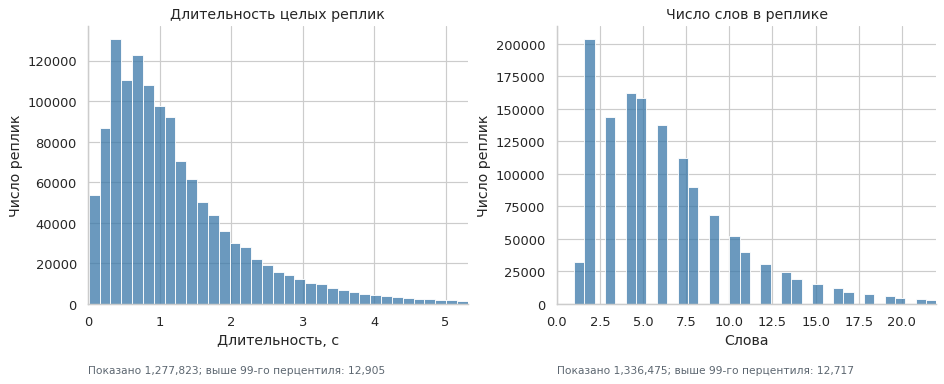

Наложения соседних реплик: 4902


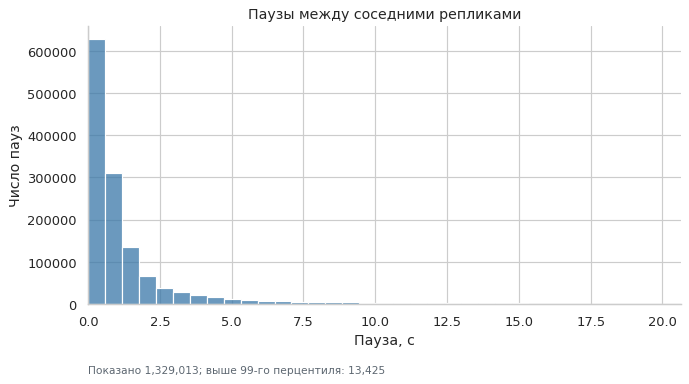

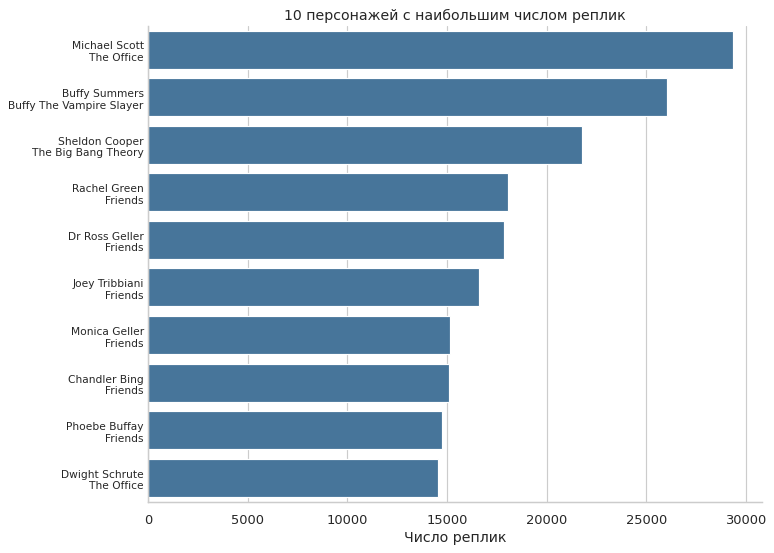

In [7]:
def utterances(text, episode):
    rows = []
    current = []

    def flush():
        if not current:
            return
        lexical = [x for x in current if any(ch.isalnum() for ch in x[3])]
        if not lexical:
            current.clear()
            return
        first, last = lexical[0], lexical[-1]
        valid = first[2] > first[1] >= 0 and last[2] > last[1] >= 0
        rows.append(
            dict(
                episode=episode,
                speaker=first[0],
                text=" ".join(x[3] for x in current if x[3]),
                start=first[1],
                end=last[2],
                valid=valid,
                conflict=any(x[4] for x in current),
            )
        )
        current.clear()

    for line in text.split("\n"):
        f = line.rstrip("\r").split(" ")
        if len(f) < 6:
            continue
        try:
            a, b = float(f[2]), float(f[3])
        except ValueError:
            flush()
            continue
        if not math.isfinite(a + b):
            flush()
            continue
        if current and (f[1] != current[-1][0] or a - current[-1][2] > 0.5):
            flush()
        current.append((f[1], a, b, f[4], f[0] != episode))
        if re.search(r'[.!?]["\']?$', f[4]):
            flush()
    flush()
    return rows


with stage("Сборка реплик"):
    records = []
    for name, path in tqdm(transcripts.items(), desc="Серии"):
        records.extend(utterances(path.read_text(), Path(name).stem))
    df = pd.DataFrame(records)
    df["seconds"] = df.end - df.start
    df["words"] = df.text.str.split().str.len()
    df["split"] = np.select(
        [
            df.episode.str.contains("Season01"),
            df.episode.str.contains("Season02|Season03"),
        ],
        ["test", "val"],
        default="train",
    )
    df["series"] = df.episode.str.split(".").str[0]
    movies = df.series.isin(["HarryPotter", "StarWars", "TheLordOfTheRings"])
    df.loc[movies, "split"] = df.loc[movies, "episode"].map(
        lambda x: (
            "test"
            if ".Episode01" in x
            else "val" if any(y in x for y in [".Episode02", ".Episode03"]) else "train"
        )
    )
    display(df.groupby("split").agg(Реплики=("text", "size"), Слова=("words", "sum")))

    # Убираем длинный хвост только из визуализации, без clip и изменения df.
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
    draw_histogram(
        axes[0],
        df.loc[df.valid & (df.seconds > 0), "seconds"],
        "Длительность целых реплик",
        "Длительность, с",
    )
    draw_histogram(axes[1], df.words, "Число слов в реплике", "Слова")
    plt.show()

    ordered = df.sort_values(["episode", "start"])
    gaps = ordered.start - ordered.groupby("episode").end.shift()
    print("Наложения соседних реплик:", int((gaps < 0).sum()))

    fig, ax = plt.subplots(figsize=(8, 4.4), layout="constrained")
    draw_histogram(ax, gaps[gaps >= 0], "Паузы между соседними репликами", "Пауза, с")
    ax.set_ylabel("Число пауз")
    plt.show()

    top = speaker_counts(df)
    fig, ax = plt.subplots(figsize=(9, 6.4), layout="constrained")
    sns.barplot(data=top, x="count", y="label", color="#3977a8", ax=ax)
    ax.set(
        title="10 персонажей с наибольшим числом реплик",
        xlabel="Число реплик",
        ylabel="",
    )
    ax.tick_params(axis="y", labelsize=9, length=0)
    plt.show()


## 4. Референсы train и общий test
Автоматически выбираем шесть целых реплик test длительностью 3–8 секунд. Для каждого голоса ищем отдельный референс train длительностью 5–10 секунд. Реплики с пересечением разных говорящих исключаем.

Все модели получают одни и те же тексты и референсы. Отдельный пример val используем для прогрева перед замером. Голосовые примеры не создаются вручную; совпадение текста синтеза с референсом не требуется.


In [8]:
def individual(s):
    return s.lower() not in {
        "all",
        "crowd",
        "multiple_persons",
        "not_available",
        "_",
        "?",
        "",
    } and not any(x in s.lower() for x in ["unknown", "@", "&"])


clips = STORE / "clips"
clips.mkdir(exist_ok=True)
small = df[df.episode.isin(audio)].copy()
small = small[small.valid & ~small.conflict & small.speaker.map(individual)]


# Не допускаем наложения любого другого говорящего на выбранное окно.
def clean_window(r):
    others = df[(df.episode == r.episode) & (df.speaker != r.speaker)]
    return not ((others.start < r.end) & (others.end > r.start)).any()


refs = {}
for r in (
    small[(small.split == "train") & small.seconds.between(5, 10)]
    .sort_values("seconds")
    .itertuples()
):
    if r.speaker not in refs and clean_window(r):
        refs[r.speaker] = r
selected = []
for r in (
    small[(small.split == "test") & small.seconds.between(3, 8)]
    .sample(frac=1, random_state=SEED)
    .itertuples()
):
    if r.speaker in refs and clean_window(r):
        selected.append(r)
        if len(selected) == COUNT:
            break
if not selected:
    raise RuntimeError("Нет подходящих целых реплик; расширьте список аудиодорожек")


def cut(r, name):
    path = clips / name
    with sf.SoundFile(audio[r.episode]) as source:
        source.seek(round(r.start * source.samplerate))
        wave = source.read(round((r.end - r.start) * source.samplerate))
        sf.write(path, wave, source.samplerate)
    return str(path)


jobs = []
for i, r in enumerate(selected):
    ref = refs[r.speaker]
    jobs.append(
        dict(
            id=i,
            text=r.text,
            ref_text=ref.text,
            ref=cut(ref, f"ref-{i}.wav"),
            original=cut(r, f"target-{i}.wav"),
            language="English",
            speaker=r.speaker,
            window=r.seconds,
        )
    )
(OUT / "jobs.json").write_text(json.dumps(jobs, ensure_ascii=False))
display(
    pd.DataFrame(jobs)[["id", "speaker", "text", "window"]].rename(
        columns={"speaker": "Персонаж", "text": "Реплика", "window": "Окно, с"}
    )
)
display(Audio(filename=jobs[0]["original"]))

val = small[
    (small.split == "val") & small.seconds.between(3, 8) & small.speaker.isin(refs)
]
if len(val):
    v = val.iloc[0]
    ref = refs[v.speaker]
    (OUT / "warmup.json").write_text(
        json.dumps(
            dict(
                text=v.text,
                language="English",
                ref=cut(ref, "warmup-ref.wav"),
                ref_text=ref.text,
            )
        )
    )


,id,Персонаж,Реплика,"Окно, с"
0,0,sheldon_cooper,So if a photon is directed through a plane wit...,5.04
1,1,leonard_hofstadter,A little extra money to get fractional T1 band...,3.28
2,2,leonard_hofstadter,I ' m not going to engage in hypotheticals her...,3.82
3,3,sheldon_cooper,"Yeah , well , it 's just some quantum mechanic...",4.70
4,4,sheldon_cooper,"Leonard , the TV is in the building , we ' ve ...",3.68
5,5,penny,"I ' m so sorry , I really thought if you guys ...",4.67


## 5. FLORES-200: предложения, полнота и длина переводов
FLORES содержит параллельные предложения без аудио. Здесь анализируем четыре языка: английский, немецкий, французский и испанский. Выводы относятся к этому подмножеству, а не ко всем 200 языкам. Каждая строка — целое предложение; слова считаем разделением по пробелам.

Первая таблица показывает объём dev/devtest и длины предложений. Вторая проверяет пустые записи, повторы и совпадение ID с английским. Повторы текста сравниваем после NFC-нормализации и удаления пробелов по краям; dev и devtest проверяем раздельно и между собой.

Последний график сопоставляет переводы с EN по `split + id`. Он показывает, насколько длиннее или короче текст, что полезно для будущей подгонки озвучки. По числу символов нельзя надёжно предсказать длительность речи. Исходные предложения не выводим и не экспортируем. FLORES используем только для анализа и оценки.


FLORES · языки:   0%|          | 0/5 [00:00<?, ?it/s]

,Язык,Разбиение,Предложения,Слова · медиана,Слова · p90,Символы · медиана,Символы · p90
0,Английский,dev,997,20.0,30.0,120.0,183.0
1,Английский,devtest,1012,21.0,31.0,124.0,185.9
2,Немецкий,dev,997,20.0,31.0,140.0,213.4
3,Немецкий,devtest,1012,21.0,31.0,146.0,219.0
4,Французский,dev,997,23.0,35.0,144.0,213.4
5,Французский,devtest,1012,24.0,36.0,149.0,223.0
6,Испанский,dev,997,24.0,36.0,143.0,219.0
7,Испанский,devtest,1012,25.0,37.0,149.0,222.0
8,Русский,dev,997,18.0,28.0,134.0,206.0
9,Русский,devtest,1012,19.0,28.0,135.0,203.0


,Язык,Пустые,Повторы ID внутри split,Повторы текста внутри split,Общие тексты dev / devtest,ID совпадают с EN
0,Английский,0,0,0,0,да
1,Немецкий,0,0,0,0,да
2,Французский,0,0,0,0,да
3,Испанский,0,0,0,1,да
4,Русский,0,0,0,0,да


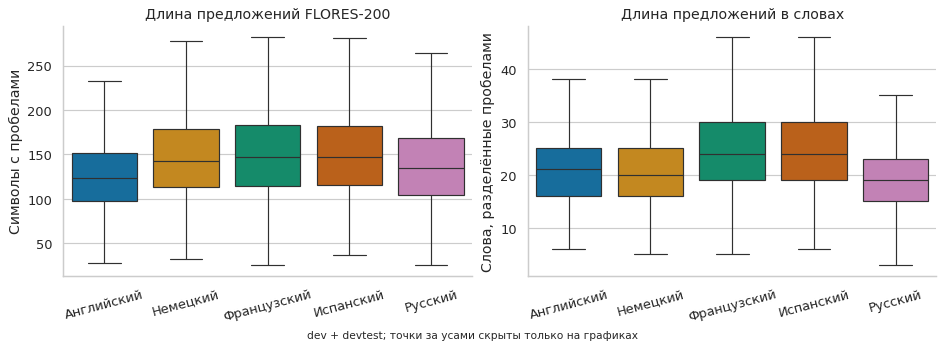

,Язык,Пары с EN,Длина к EN · медиана,Длина к EN · p90
0,Немецкий,2009,1.16,1.34
1,Французский,2009,1.19,1.38
2,Испанский,2009,1.18,1.42
3,Русский,2009,1.08,1.31


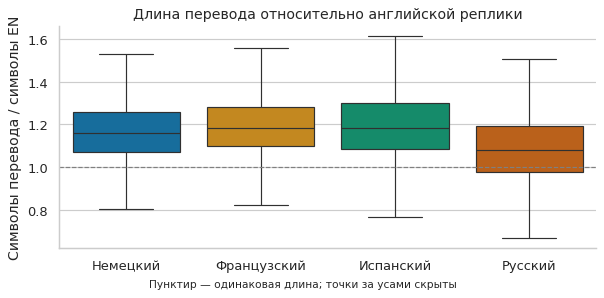

Испанский: 1 общий текст в dev и devtest. При сравнении моделей учитывайте этот повтор отдельно.
Длина перевода помогает оценить нагрузку на озвучку, но не заменяет длительность аудио.


In [9]:
def flores_rows(table, language, split):
    """Оставить для анализа числа и отпечатки; исходные тексты не выводить."""
    records = []
    for row in table.itertuples(index=False):
        text = row.sentence if isinstance(row.sentence, str) else ""
        normalized = unicodedata.normalize("NFC", text).strip()
        records.append(
            {
                "id": row.id,
                "language": language,
                "split": split,
                "length": len(text),
                # Единая простая оценка для четырёх языков с пробельным письмом.
                "words": len(text.split()),
                "empty": not normalized,
                "fingerprint": hashlib.sha256(normalized.encode()).hexdigest(),
            }
        )
    return records


with stage("FLORES · кэш и статистика"):
    rows = []
    frev = "71abf77d8b7beb5cfef59898d6b24d92ab7654fc"
    fi = API.dataset_info("facebook/flores", revision=frev, files_metadata=True)
    fm = {file.rfilename: file for file in fi.siblings}
    languages = {
        "eng_Latn": "Английский",
        "deu_Latn": "Немецкий",
        "fra_Latn": "Французский",
        "spa_Latn": "Испанский",
        "rus_Cyrl": "Русский",
    }
    for lang in tqdm(languages, desc="FLORES · языки"):
        for split in ["dev", "devtest"]:
            name = f"data/language/{lang}/{split}-00000-of-00001.parquet"
            table = pd.read_parquet(download("facebook/flores", frev, fm[name]))
            rows.extend(flores_rows(table, lang, split))
    del table
    flores = pd.DataFrame(rows)
    flores["Язык"] = flores.language.map(languages)

# Число предложений и длины считаем по каждому разбиению отдельно.
summary = (
    flores.groupby(["Язык", "split"], sort=False)
    .agg(
        **{
            "Предложения": ("id", "size"),
            "Слова · медиана": ("words", "median"),
            "Слова · p90": ("words", lambda s: s.quantile(0.90)),
            "Символы · медиана": ("length", "median"),
            "Символы · p90": ("length", lambda s: s.quantile(0.90)),
        }
    )
    .reset_index()
    .rename(columns={"split": "Разбиение"})
)
display(summary.round(1))

checks = []
for lang, label in languages.items():
    subset = flores[flores.language.eq(lang)]
    dev = subset[subset.split.eq("dev")]
    test = subset[subset.split.eq("devtest")]
    aligned = True
    for split in ["dev", "devtest"]:
        expected = set(
            flores.loc[flores.language.eq("eng_Latn") & flores.split.eq(split), "id"]
        )
        actual = set(subset.loc[subset.split.eq(split), "id"])
        aligned = aligned and actual == expected
    checks.append(
        {
            "Язык": label,
            "Пустые": int(subset["empty"].sum()),
            "Повторы ID внутри split": int(subset.duplicated(["split", "id"]).sum()),
            "Повторы текста внутри split": int(
                subset.duplicated(["split", "fingerprint"]).sum()
            ),
            "Общие тексты dev / devtest": len(
                set(dev.fingerprint) & set(test.fingerprint)
            ),
            "ID совпадают с EN": "да" if aligned else "нет",
        }
    )
display(pd.DataFrame(checks))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, field, title, ylabel in [
    (axes[0], "length", "Длина предложений FLORES-200", "Символы с пробелами"),
    (axes[1], "words", "Длина предложений в словах", "Слова, разделённые пробелами"),
]:
    sns.boxplot(
        data=flores,
        x="Язык",
        y=field,
        hue="Язык",
        legend=False,
        showfliers=False,
        ax=ax,
    )
    ax.set(title=title, xlabel="", ylabel=ylabel)
    ax.tick_params(axis="x", labelrotation=15)
fig.supxlabel("dev + devtest; точки за усами скрыты только на графиках", fontsize=9)
plt.show()
plt.close(fig)

# Сопоставляем только одинаковые split + id, а не порядковые номера строк.
english = flores[flores.language.eq("eng_Latn")][["split", "id", "length"]]
paired = flores[flores.language.ne("eng_Latn")].merge(
    english.rename(columns={"length": "english_length"}),
    on=["split", "id"],
    validate="many_to_one",
)
paired = paired[paired.english_length.gt(0)].copy()
paired["ratio"] = paired.length / paired.english_length
ratios = (
    paired.groupby("Язык", sort=False)
    .agg(
        **{
            "Пары с EN": ("id", "size"),
            "Длина к EN · медиана": ("ratio", "median"),
            "Длина к EN · p90": ("ratio", lambda s: s.quantile(0.9)),
        }
    )
    .reset_index()
)
display(ratios.round(2))

fig, ax = plt.subplots(figsize=(7, 3.4), layout="constrained")
sns.boxplot(
    data=paired, x="Язык", y="ratio", hue="Язык", legend=False, showfliers=False, ax=ax
)
ax.axhline(1, color="gray", linestyle="--", linewidth=1)
ax.set(
    title="Длина перевода относительно английской реплики",
    xlabel="",
    ylabel="Символы перевода / символы EN",
)
fig.supxlabel("Пунктир — одинаковая длина; точки за усами скрыты", fontsize=9)
plt.show()
plt.close(fig)

# Только агрегаты: ни исходные предложения, ни их отпечатки не экспортируются.
for row in checks:
    if row["Общие тексты dev / devtest"]:
        print(
            f"{row['Язык']}: {row['Общие тексты dev / devtest']} общий текст в dev и devtest. "
            "При сравнении моделей учитывайте этот повтор отдельно."
        )
print(
    "Длина перевода помогает оценить нагрузку на озвучку, но не заменяет длительность аудио."
)


По проверенному кэшу: по **997 предложений dev и 1012 devtest на язык**, всего 8036 строк. Пустых предложений и повторов ID внутри разбиений нет; наборы ID совпадают с английским. В испанском найден один общий текст между dev и devtest.

Медианная длина немецкого перевода — **1,16** длины EN, французского — **1,19**, испанского — **1,18**, русского - **1.08**. Тексты переводов обычно длиннее, поэтому для будущего дубляжа нужно отдельно проверить длительность озвучки. Эти цифры не измеряют качество перевода.


## 6. Подготовка TTS: SDK, веса и целостность
Основной эксперимент — EN→EN: синтезируем тестовую реплику голосом из референса. Сначала устанавливаем SDK и проверяем импорт/CUDA, затем скачиваем веса. Недособранное окружение не считаем готовым.

Кэш библиотек остаётся локально. Большой общий архив на Drive больше не создаётся после каждой модели — именно эта операция в сохранённом запуске уже занимала 950 секунд за один проход. CosyVoice 2/3 используют одно окружение; их нативный PyTorch-инференс не требует TensorRT-файлов, batch-токенизаторов и альтернативного `llm.rl.pt`. Эти файлы больше не загружаются. Для выбранных репозиториев это сокращает новые загрузки примерно на 5,1 ГБ. Уже существующие файлы весов автоматически не удаляем.

При первой проверке читаем веса и считаем SHA-256, а для обычных Git-файлов — Git SHA-1. Результат сохраняем вместе с размером и временем изменения. Если версия, контрольная сумма из метаданных, размер и время изменения совпадают с прошлой успешной проверкой, повторно гигабайты с Drive не читаем. Изменённые файлы проверяем заново, повреждённые перезагружаем. Для полного чтения всех файлов включите `RECHECK_MODEL_WEIGHTS`.

У каждой модели отдельно измеряются установка SDK, загрузка весов и проверка. Полный выигрыш по сравнению с 50 минутами требует замера в вашем runtime: скорость сети и Drive меняется. При первом запуске скачивание весов и установка CUDA-библиотек всё ещё могут занимать заметное время.

Выбранный backend Higgs не поддерживает T4 и будет пропущен до скачивания весов. Для MOSS устанавливаем официальный `torch-runtime`. Ошибки подготовки показываются в секции инференса с отдельными журналами.

В Kaggle все крупные модельные кэши направлены на временный диск, включая ASR, ECAPA и WavLM. Подключённый приватный Input используется без полной копии весов в output. Проверка SDK включает небольшую операцию CUDA до загрузки весов, чтобы раньше выявить несовместимый GPU/драйвер.


In [10]:
# @title Адаптеры и окружения TTS — развернуть код
import fnmatch

WORKER = r"""
import os, sys, json, time, random
from pathlib import Path
import numpy as np, torch, soundfile as sf

key, path, jobs_file, output = sys.argv[1:]
jobs = json.loads(Path(jobs_file).read_text())
out = Path(output)
out.mkdir(exist_ok=True, parents=True)
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)
dtype = torch.float16
if key == "qwen":
    from qwen_tts import Qwen3TTSModel

    # Qwen FP16 может переполняться при семплировании. На T4 используем FP32;
    # Ampere и новее поддерживают нативный BF16 (Qwen3-TTS issue #43).
    qwen_dtype = (
        torch.bfloat16
        if torch.cuda.get_device_capability(0)[0] >= 8
        else torch.float32
    )
    print(f"Qwen: cuda:0, {qwen_dtype}", file=sys.stderr, flush=True)
    model = Qwen3TTSModel.from_pretrained(
        path, device_map="cuda:0", dtype=qwen_dtype, attn_implementation="sdpa"
    )

    def generate(j):
        waves, sr = model.generate_voice_clone(
            text=j["text"],
            language=j["language"],
            ref_audio=j["ref"],
            ref_text=j["ref_text"],
        )
        return waves[0], sr

elif key in ["cosy2", "cosy3"]:
    from cosyvoice.cli.cosyvoice import AutoModel

    model = AutoModel(model_dir=path, fp16=True)

    def generate(j):
        prefix = (
            "You are a helpful assistant.<|endofprompt|>" + j["ref_text"]
            if key == "cosy3"
            else j["ref_text"]
        )
        chunks = model.inference_zero_shot(j["text"], prefix, j["ref"], stream=True)
        return chunks, model.sample_rate

elif key == "vox":
    from voxcpm import VoxCPM

    # Eager CUDA обходит несовместимый путь Dynamo / einops.
    model = VoxCPM.from_pretrained(path, optimize=False)

    def generate(j):
        return (
            model.generate(
                text=j["text"], prompt_wav_path=j["ref"], prompt_text=j["ref_text"]
            ),
            model.tts_model.sample_rate,
        )

elif key == "omni":
    from omnivoice import OmniVoice

    model = OmniVoice.from_pretrained(path, device_map="cuda:0", dtype=dtype)

    def generate(j):
        return (
            model.generate(text=j["text"], ref_audio=j["ref"], ref_text=j["ref_text"])[
                0
            ],
            24000,
        )

elif key == "moss":
    from transformers import AutoModel, AutoProcessor

    proc = AutoProcessor.from_pretrained(path, trust_remote_code=True)
    proc.audio_tokenizer = proc.audio_tokenizer.to("cuda")
    model = (
        AutoModel.from_pretrained(
            path, trust_remote_code=True, torch_dtype=dtype, attn_implementation="sdpa"
        )
        .to("cuda")
        .eval()
    )

    def generate(j):
        batch = proc(
            [[proc.build_user_message(text=j["text"], reference=[j["ref"]])]],
            mode="generation",
        )
        with torch.inference_mode():
            result = model.generate(
                input_ids=batch["input_ids"].to("cuda"),
                attention_mask=batch["attention_mask"].to("cuda"),
                max_new_tokens=512,
            )
        msg = proc.decode(result)[0]
        return msg.audio_codes_list[0], proc.model_config.sampling_rate

elif key == "higgs":
    import subprocess, requests, io

    server = subprocess.Popen(
        [
            str(Path(sys.executable).parent / "sgl-omni"),
            "serve",
            "--model-path",
            path,
            "--port",
            "8917",
        ],
        stdout=(out / "server.log").open("w"),
        stderr=subprocess.STDOUT,
    )
    for attempt in range(120):
        try:
            if requests.get("http://127.0.0.1:8917/health", timeout=2).ok:
                break
        except requests.RequestException:
            pass
        if server.poll() is not None:
            raise RuntimeError("Higgs backend завершился при запуске")
        time.sleep(5)
    else:
        raise TimeoutError("Higgs backend не готов")

    def generate(j):
        def packets():
            response = requests.post(
                "http://127.0.0.1:8917/v1/audio/speech",
                json={
                    "input": j["text"],
                    "references": [{"audio_path": j["ref"], "text": j["ref_text"]}],
                    "stream": True,
                    "max_new_tokens": 512,
                },
                stream=True,
                timeout=120,
            )
            response.raise_for_status()
            import base64

            for line in response.iter_lines():
                if not line.startswith(b"data: ") or line == b"data: [DONE]":
                    continue
                item = json.loads(line[6:])
                data = (item.get("audio") or {}).get("data")
                if data:
                    wave, rate = sf.read(
                        io.BytesIO(base64.b64decode(data)), dtype="float32"
                    )
                    if rate != 24000:
                        raise ValueError("Непредвиденная частота Higgs")
                    yield {"tts_speech": torch.from_numpy(wave)}

        return packets(), 24000

else:
    raise ValueError(key)
warmup = out.parent / "warmup.json"
if warmup.exists():
    value, rate = generate(json.loads(warmup.read_text()))
    if key in ["cosy2", "cosy3", "higgs"]:
        for packet in value:
            pass
    torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()
print(json.dumps({"event": "ready"}), flush=True)
for index, j in enumerate(jobs):
    print(json.dumps({"event": "start", "index": index}), flush=True)
    torch.cuda.synchronize()
    begin = time.perf_counter()
    value, sr = generate(j)
    first = None
    if key in ["cosy2", "cosy3", "higgs"]:
        chunks = []
        for packet in value:
            x = packet["tts_speech"].detach().float().cpu().numpy().reshape(-1)
            if len(x) and first is None:
                first = time.perf_counter() - begin
            chunks.append(x)
        wave = np.concatenate(chunks)
    else:
        wave = (
            value.detach().float().cpu().numpy()
            if torch.is_tensor(value)
            else np.asarray(value)
        )
        wave = wave.reshape(-1)
    torch.cuda.synchronize()
    elapsed = time.perf_counter() - begin
    dest = out / f"{j['id']}.wav"
    sf.write(dest, wave, sr)
    record = dict(
        model=key,
        id=j["id"],
        file=str(dest),
        seconds=len(wave) / sr,
        time=elapsed,
        ttfa=first,
        rtf=elapsed / (len(wave) / sr),
        memory=None if key == "higgs" else torch.cuda.max_memory_allocated() / 2**30,
    )
    print(json.dumps({"event": "result", **record}), flush=True)
if key == "higgs":
    server.terminate()
    server.wait(timeout=20)
"""
worker = ROOT / "worker.py"
worker.write_text(WORKER)
# Независимые окружения предотвращают конфликт Transformers 4/5 и PyTorch.
COSY_REVISION = "074ca6dc9e80a2f424f1f74b48bdd7d3fea531cc"
COSY_PACKAGES = [
    "torch==2.3.1",
    "torchaudio==2.3.1",
    "numpy==1.26.4",
    "transformers==4.51.3",
    "conformer==0.3.2",
    "diffusers==0.29.0",
    "hydra-core==1.3.2",
    "HyperPyYAML==1.2.3",
    "inflect==7.3.1",
    "librosa==0.10.2",
    "modelscope==1.20.0",
    "onnxruntime-gpu==1.18.0",
    "openai-whisper==20231117",
    "omegaconf==2.3.0",
    "wetext==0.0.4",
    "x-transformers==2.11.24",
    "pyworld==0.3.4",
    "gdown==5.1.0",
    "setuptools<80",
    "lightning==2.2.4",
    "matplotlib==3.7.5",
    "pyarrow==18.1.0",
    "rich",
    "wget",
    "einops",
]
models = {
    "qwen": (
        "Qwen/Qwen3-TTS-12Hz-0.6B-Base",
        [
            "qwen-tts==0.1.1",
            "torch==2.8.0",
            "torchaudio==2.8.0",
        ],
    ),
    "cosy2": ("FunAudioLLM/CosyVoice2-0.5B", COSY_PACKAGES),
    "cosy3": ("FunAudioLLM/Fun-CosyVoice3-0.5B-2512", COSY_PACKAGES),
    "vox": (
        "openbmb/VoxCPM2",
        ["voxcpm", "torch==2.8.0", "torchaudio==2.8.0", "torchcodec==0.7.0"],
    ),
    "omni": ("k2-fsa/OmniVoice", ["omnivoice", "torch==2.8.0", "torchaudio==2.8.0"]),
    "moss": (
        "OpenMOSS-Team/MOSS-TTS-Local-Transformer",
        [
            "moss-tts[torch-runtime] @ git+https://github.com/OpenMOSS/MOSS-TTS.git@934d6826b084c46a0d033402174d5f8ac4ed2519",
        ],
    ),
    "higgs": (
        "bosonai/higgs-tts-3-4b",
        [
            "git+https://github.com/sgl-project/sglang-omni.git@f78455b6edc2aedac2001528e2aa0265495f98f4",
        ],
    ),
}
PROBES = {
    "qwen": "from qwen_tts import Qwen3TTSModel",
    "cosy2": "from cosyvoice.cli.cosyvoice import AutoModel; from cosyvoice.flow.decoder import CausalConditionalDecoder; from cosyvoice.flow.flow_matching import ConditionalCFM",
    "cosy3": "from cosyvoice.cli.cosyvoice import AutoModel; from cosyvoice.flow.decoder import CausalConditionalDecoder; from cosyvoice.flow.flow_matching import ConditionalCFM",
    "vox": "from voxcpm import VoxCPM",
    "omni": "from omnivoice import OmniVoice",
    "moss": "from transformers import AutoModel, AutoProcessor; import torchcodec",
    "higgs": "import sglang_omni",
}


# YAML импортирует и обработчики train; проверяем все ссылки до весов.
COSY_CONFIG_PROBE = r"""
import pydoc
import re
import sys
from pathlib import Path

repo = Path(sys.argv[1])
for variant in ("cosyvoice2", "cosyvoice3"):
    config = repo / "examples" / "libritts" / variant / "conf" / f"{variant}.yaml"
    symbols = sorted(set(re.findall(
        r"!(?:new|name|apply):([A-Za-z_][A-Za-z0-9_.]*)", config.read_text()
    )))
    if not symbols:
        raise ValueError(f"В конфигурации нет Python-объектов: {config}")
    for symbol in symbols:
        if pydoc.locate(symbol) is None:
            raise ImportError(f"Недоступен объект конфигурации: {symbol}")
    print(f"{variant}: проверены {len(symbols)} объектов конфигурации", flush=True)
"""
cosy_probe_file = ROOT / "check-cosy-configs.py"
cosy_probe_file.write_text(COSY_CONFIG_PROBE)


def prepare_environment(key, packages):
    # uv создаёт venv без ensurepip. Недособранная среда не считается готовой.
    env = ROOT / "envs-v2" / ("cosy2" if key.startswith("cosy") else key)
    python = env / "bin/python"
    version = "3.10" if key.startswith("cosy") else "3.11"
    uv = [sys.executable, "-m", "uv"]
    if not python.exists():
        shell(uv + ["venv", "--python", version, str(env)], label=f"{key}-venv")

    if key.startswith("cosy"):
        repo_dir = ROOT / "CosyVoice"
        if not (repo_dir / ".git").exists():
            shell(
                [
                    "git",
                    "clone",
                    "https://github.com/FunAudioLLM/CosyVoice.git",
                    str(repo_dir),
                ],
                label="cosy-source",
            )
        shell(
            ["git", "-C", str(repo_dir), "checkout", COSY_REVISION],
            label="cosy-revision",
        )
        shell(
            [
                "git",
                "-C",
                str(repo_dir),
                "submodule",
                "update",
                "--init",
                "--recursive",
            ],
            label="cosy-submodules",
        )
        os.environ["PYTHONPATH"] = os.pathsep.join(
            [
                str(repo_dir),
                str(repo_dir / "third_party/Matcha-TTS"),
            ]
        )

    signature = {
        "recipe": 4 if key.startswith("cosy") else 3,
        "python": version,
        "packages": packages,
        "probe": PROBES[key],
    }
    marker = env / "packages.json"
    cached = marker.exists() and json.loads(marker.read_text()) == signature
    if not cached:
        marker.unlink(missing_ok=True)
        # MOSS требует собственного CUDA-стека; дополнительные extras обязательны.
        indexes = ["--torch-backend", "cu128"] if key == "moss" else []
        # Старые Whisper/pyworld используют pkg_resources даже при сборке.
        # Обычная зависимость setuptools<80 не ограничивает изолированную сборку.
        build_constraints = ROOT / "build-constraints.txt"
        build_constraints.write_text("setuptools<80\n")
        shell(
            uv
            + [
                "pip",
                "install",
                "--python",
                str(python),
                "--build-constraints",
                str(build_constraints),
                *indexes,
                *packages,
                "soundfile",
            ],
            timeout=2400,
            label=f"{key}-packages",
        )

    probe = "import torch, torchaudio, soundfile; " + PROBES[key]
    probe += "; assert torch.cuda.is_available(), 'CUDA недоступна в окружении модели'"
    probe += "; _ = torch.ones(1, device='cuda').sum().item()"
    try:
        shell([str(python), "-c", probe], timeout=180, label=f"{key}-import-cuda")
        if key.startswith("cosy"):
            shell(
                [str(python), str(cosy_probe_file), str(repo_dir)],
                timeout=180,
                label=f"{key}-yaml-imports",
            )
    except RuntimeError:
        marker.unlink(missing_ok=True)
        raise
    marker.write_text(json.dumps(signature, indent=2))
    return str(python)


def required_model_files(key, files):
    """Нативный PyTorch-инференс CosyVoice не использует TRT и batch-токенизатор."""
    if not key.startswith("cosy"):
        return list(files)
    ignored = (
        "flow.decoder.estimator*.onnx",
        "speech_tokenizer_*.batch.onnx",
        "llm.rl.pt",
        "asset/*",
    )
    return [
        file
        for file in files
        if not any(fnmatch.fnmatch(file.rfilename, pattern) for pattern in ignored)
    ]


def verify_model_file(path, expected_size, expected_sha, git_blob, ledger, force=False):
    """Повторно читать вес только при изменении файла или полной перепроверке."""
    path = Path(path)
    if not path.is_file():
        return False
    stat = path.stat()
    if stat.st_size != expected_size:
        return False
    fingerprint = {
        "size": stat.st_size,
        "mtime_ns": stat.st_mtime_ns,
        "sha256": expected_sha,
        "git_blob": git_blob,
    }
    cache_key = str(path)
    if not force and ledger.get(cache_key) == fingerprint:
        return True

    if expected_sha or git_blob:
        digest = hashlib.sha256() if expected_sha else hashlib.sha1()
        if not expected_sha:
            digest.update(f"blob {stat.st_size}\0".encode())
        with path.open("rb") as stream:
            for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
                digest.update(block)
        if digest.hexdigest() != (expected_sha or git_blob):
            ledger.pop(cache_key, None)
            return False
    ledger[cache_key] = fingerprint
    return True


def ensure_model_file(path, repo, revision, meta, ledger, force=False):
    lfs = meta.lfs
    sha = lfs.get("sha256") if isinstance(lfs, dict) else getattr(lfs, "sha256", None)
    blob = None if sha else getattr(meta, "blob_id", None)
    if verify_model_file(path, meta.size, sha, blob, ledger, force=force):
        return

    # HF может сохранить существующий snapshot при force_download. Убираем только
    # повреждённый локальный указатель; исходный readonly Input не изменяется.
    Path(path).unlink(missing_ok=True)
    hf_hub_download(
        repo,
        meta.rfilename,
        revision=revision,
        token=TOKEN,
        cache_dir=WEIGHTS_CACHE / "models",
        force_download=True,
    )
    if not verify_model_file(path, meta.size, sha, blob, ledger, force=True):
        raise ValueError(f"Контрольная сумма не совпала: {meta.rfilename}")


locks_file = STORE / "model-revisions.json"
locks = json.loads(locks_file.read_text()) if locks_file.exists() else {}
paths = {}
interpreters = {}
checks_file = CACHE / "verified-model-files.json"
try:
    checks = json.loads(checks_file.read_text()) if checks_file.exists() else {}
except (OSError, ValueError):
    checks = {}
RECHECK_MODEL_WEIGHTS = False  # @param {type:"boolean"}

if GPU:
    for key, (repo, packages) in tqdm(models.items(), desc="Окружения / модели"):
        try:
            if key == "higgs" and torch.cuda.get_device_capability(0)[0] < 8:
                statuses.append(
                    dict(
                        Модель=key,
                        Статус="backend несовместим",
                        Причина="Выбранный SGLang backend не поддерживает T4. Веса не скачиваются.",
                    )
                )
                continue

            with stage(f"{key} · SDK и CUDA"):
                python = prepare_environment(key, packages)

            with stage(f"{key} · веса: кэш / загрузка"):
                if repo not in locks:
                    locks[repo] = API.model_info(repo).sha
                    locks_file.write_text(json.dumps(locks, indent=2))
                metadata = API.model_info(
                    repo, revision=locks[repo], files_metadata=True
                )
                needed = required_model_files(key, metadata.siblings)
                paths[key] = snapshot_download(
                    repo,
                    revision=locks[repo],
                    token=TOKEN,
                    cache_dir=WEIGHTS_CACHE / "models",
                    allow_patterns=[file.rfilename for file in needed],
                )

            with stage(f"{key} · проверка файлов"):
                for file in tqdm(needed, desc=f"{key} · целостность"):
                    local = Path(paths[key]) / file.rfilename
                    ensure_model_file(
                        local,
                        repo,
                        locks[repo],
                        file,
                        checks,
                        force=RECHECK_MODEL_WEIGHTS,
                    )
                checks_file.write_text(json.dumps(checks, indent=2))
            interpreters[key] = python
        except (RuntimeError, OSError, TimeoutError, ValueError) as error:
            statuses.append(
                dict(Модель=key, Статус="ошибка подготовки", Причина=str(error))
            )
else:
    print("GPU отсутствует: веса TTS не скачиваются, метрики генерации не заполняются.")

preparation_rows = [
    row for row in timings if any(row["Этап"].startswith(f"{key} · ") for key in models)
]
if preparation_rows:
    display(pd.DataFrame(preparation_rows)[["Этап", "Секунды"]].round(1))


Окружения / модели:   0%|          | 0/7 [00:00<?, ?it/s]

qwen · целостность:   0%|          | 0/13 [00:00<?, ?it/s]

cosy2 · целостность:   0%|          | 0/16 [00:00<?, ?it/s]

cosy3 · целостность:   0%|          | 0/16 [00:00<?, ?it/s]

vox · целостность:   0%|          | 0/9 [00:00<?, ?it/s]

omni · целостность:   0%|          | 0/13 [00:00<?, ?it/s]

moss · целостность:   0%|          | 0/20 [00:00<?, ?it/s]

,Этап,Секунды
0,qwen · SDK и CUDA,71.1
1,qwen · веса: кэш / загрузка,5.1
2,qwen · проверка файлов,15.1
3,cosy2 · SDK и CUDA,94.2
4,cosy2 · веса: кэш / загрузка,13.6
5,cosy2 · проверка файлов,11.7
6,cosy3 · SDK и CUDA,16.8
7,cosy3 · веса: кэш / загрузка,27.5
8,cosy3 · проверка файлов,14.8
9,vox · SDK и CUDA,26.6


## 7. Sidon: очистка референсов
Sidon обрабатывает исходное аудио референса перед клонированием. Сравним Qwen с исходным и очищенным референсом на тех же шести текстах. Так можно проверить, меняет ли очистка сходство голоса и разборчивость синтеза.

Используем официальный JIT-пайплайн SaruLab. Загрузка и инициализация не входят в лимит; сама очистка и дополнительные генерации входят. Если Qwen не подготовлен, сравнение Sidon пропускается с явным статусом.


In [11]:
if GPU and "qwen" in interpreters and compute < LIMIT:
    try:
        with stage("Sidon · инициализация"):
            shell(
                [
                    sys.executable,
                    "-m",
                    "pip",
                    "install",
                    "-q",
                    "transformers==4.57.3",
                    "torchaudio",
                ]
            )
            import torch, torchaudio
            from transformers import SeamlessM4TFeatureExtractor

            fe_path = hf_hub_download(
                "sarulab-speech/sidon-v0.1",
                "feature_extractor_cuda.pt",
                token=TOKEN,
                cache_dir=WEIGHTS_CACHE / "hf/hub",
            )
            dec_path = hf_hub_download(
                "sarulab-speech/sidon-v0.1",
                "decoder_cuda.pt",
                token=TOKEN,
                cache_dir=WEIGHTS_CACHE / "hf/hub",
            )
            fe = torch.jit.load(fe_path, map_location="cuda").eval()
            decoder = torch.jit.load(dec_path, map_location="cuda").eval()
            preprocessor = SeamlessM4TFeatureExtractor.from_pretrained(
                "facebook/w2v-bert-2.0", cache_dir=WEIGHTS_CACHE / "hf/hub"
            )
        cleaned = []
        with stage("Sidon · очистка", counted=True), torch.inference_mode():
            for j in tqdm(jobs, desc="Референсы Sidon"):
                wave, sr = sf.read(j["ref"], dtype="float32")
                wave = torch.from_numpy(wave).reshape(1, -1)
                wave = wave * 0.9 / max(float(wave.abs().max()), 1e-8)
                wave = torchaudio.functional.highpass_biquad(wave, sr, 50)
                wave = torchaudio.functional.resample(wave, sr, 16000)
                length = round(wave.shape[-1] * 3)
                chunk = torch.nn.functional.pad(wave.flatten(), (0, 24000))
                inputs = preprocessor(
                    torch.nn.functional.pad(chunk, (160, 160)),
                    sampling_rate=16000,
                    return_tensors="pt",
                )
                feature = fe(inputs["input_features"].to("cuda"))["last_hidden_state"]
                restored = (
                    decoder(feature.transpose(1, 2))
                    .flatten()[:-960][:length]
                    .cpu()
                    .numpy()
                )
                dest = clips / f"sidon-{j['id']}.wav"
                sf.write(dest, restored, 48000)
                cleaned.append({**j, "ref": str(dest)})
        del fe, decoder
        torch.cuda.empty_cache()
        # A/B does not reuse synthesis cache: only the reference changes.
        clean_jobs = OUT / "sidon-jobs.json"
        clean_jobs.write_text(json.dumps(cleaned))
        interpreters["qwen+Sidon"] = interpreters["qwen"]
        paths["qwen+Sidon"] = paths["qwen"]
    except Exception as error:
        # Optional reference cleaning must not block the main TTS comparison.
        interpreters.pop("qwen+Sidon", None)
        statuses.append(
            dict(Модель="Sidon", Статус="ошибка очистки", Причина=redact(str(error)))
        )
        status("Sidon недоступен; продолжаем TTS с исходными референсами")
    finally:
        for name in ("fe", "decoder", "feature"):
            globals().pop(name, None)
        torch.cuda.empty_cache()


Референсы Sidon:   0%|          | 0/6 [00:00<?, ?it/s]

## 8. Инференс и измерение времени
Модели запускаются по очереди, чтобы освобождать GPU между ними. Инициализация и прогрев заканчиваются сигналом ready; после него начинается учёт вычислительного времени. На запуск и подготовку ответа есть таймауты, чтобы зависший процесс не останавливал весь ноутбук.

Для каждой реплики сохраняем время генерации, длительность аудио, RTF и пиковую память процесса. Задержку до первого аудиочанка измеряем только при настоящем стриминге. Если SDK возвращает только готовую запись, это значение отсутствует.

В конце выводим статус каждой модели. Подробности ошибок свёрнуты под таблицей. Отсутствие результата не означает нулевую ошибку: модель без синтеза в сравнение качества не попадает.


In [12]:
import queue

results = []
for key in tqdm(
    list(models) + (["qwen+Sidon"] if "qwen+Sidon" in interpreters else []),
    desc="TTS-модели",
):
    if key not in interpreters:
        if not any(row["Модель"] == key for row in statuses):
            statuses.append(
                dict(Модель=key, Статус="не запущена", Причина="GPU отсутствует")
            )
        continue
    if compute >= LIMIT:
        statuses.append(
            dict(Модель=key, Статус="не запущена", Причина="Вычислительный лимит")
        )
        continue
    p = subprocess.Popen(
        [
            interpreters[key],
            str(worker),
            key.split("+")[0],
            paths[key],
            str(OUT / ("sidon-jobs.json" if "+" in key else "jobs.json")),
            str(OUT / key),
        ],
        stdout=subprocess.PIPE,
        stderr=(OUT / f"{key}.log").open("w"),
        text=True,
        start_new_session=True,
    )
    messages = queue.Queue()

    def read_pipe(pipe):
        for line in pipe:
            try:
                messages.put(json.loads(line))
            except json.JSONDecodeError:
                pass
        messages.put({"event": "exit"})

    threading.Thread(target=read_pipe, args=(p.stdout,), daemon=True).start()
    ready = False
    begin = time.monotonic()
    last = begin
    inference_start = None
    bar = tqdm(total=len(jobs), desc=f"{key} · реплики")
    try:
        while True:
            now = time.monotonic()
            if (not ready and now - begin > 600) or (
                ready and now - inference_start > LIMIT - compute
            ):
                import signal

                os.killpg(p.pid, signal.SIGKILL)
                p.wait()
                statuses.append(
                    dict(Модель=key, Статус="таймаут", Причина="Лимит времени")
                )
                break
            try:
                msg = messages.get(timeout=5)
            except queue.Empty:
                status(
                    f'{key} · {"инференс" if ready else "инициализация"} · {now-begin:.0f} с · последнее событие {now-last:.0f} с назад'
                )
                continue
            last = time.monotonic()
            if msg["event"] == "ready":
                ready = True
                inference_start = last
            elif msg["event"] == "result":
                results.append({**msg, "model": key})
                bar.update(1)
            elif msg["event"] == "exit":
                p.wait()
                log_path = OUT / f"{key}.log"
                detail = redact(log_path.read_text(errors="replace"))
                log_path.write_text(detail)
                tail = "\n".join(detail.splitlines()[-12:])[-2500:]
                statuses.append(
                    dict(
                        Модель=key,
                        Статус="завершена" if p.returncode == 0 else "ошибка инференса",
                        Причина=(
                            f"код {p.returncode}; журнал {log_path}\n{tail}"
                            if p.returncode
                            else "Все реплики обработаны"
                        ),
                    )
                )
                break
    finally:
        bar.close()
        import signal

        try:
            os.killpg(p.pid, signal.SIGTERM)
        except ProcessLookupError:
            pass
        if p.poll() is None:
            p.wait(timeout=20)
        if inference_start:
            compute += time.monotonic() - inference_start
    pd.DataFrame(results).to_json(OUT / "inference.json", orient="records", indent=2)
display(pd.DataFrame(statuses).drop(columns="Причина", errors="ignore"))
for row in statuses:
    if row.get("Причина") and row["Статус"] != "завершена":
        display(
            HTML(
                f"<details><summary>{escape(row['Модель'])}: {escape(row['Статус'])}</summary>"
                f"<pre style='white-space:pre-wrap'>{escape(row['Причина'])}</pre></details>"
            )
        )


TTS-модели:   0%|          | 0/8 [00:00<?, ?it/s]

qwen · реплики:   0%|          | 0/6 [00:00<?, ?it/s]

cosy2 · реплики:   0%|          | 0/6 [00:00<?, ?it/s]

cosy3 · реплики:   0%|          | 0/6 [00:00<?, ?it/s]

vox · реплики:   0%|          | 0/6 [00:00<?, ?it/s]

omni · реплики:   0%|          | 0/6 [00:00<?, ?it/s]

moss · реплики:   0%|          | 0/6 [00:00<?, ?it/s]

qwen+Sidon · реплики:   0%|          | 0/6 [00:00<?, ?it/s]

,Модель,Статус
0,higgs,backend несовместим
1,qwen,завершена
2,cosy2,завершена
3,cosy3,завершена
4,vox,завершена
5,omni,завершена
6,moss,завершена
7,qwen+Sidon,завершена


## 9. Разборчивость, сходство голоса и прослушивание
Whisper распознаёт оригинал и синтез. WER/CER сравнивают распознанный текст с заданной репликой; исходное аудио служит контрольным уровнем ошибок самого распознавателя. ECAPA оценивает сходство синтеза с исходным голосом. Также сравниваем длительности.

Эти метрики отвечают на разные вопросы и не заменяют прослушивание. На шести примерах результаты предварительные: близкие значения ещё не доказывают превосходство модели. Таблица включает только реально полученные записи.

Выберите реплику в списке, чтобы сравнить аудио разных моделей. Одновременно показывается один пример; плееры не загружают все записи при пролистывании. Длина демонстрации ограничена 15 секундами.


Whisper · токенизатор и настройки:   0%|          | 0/10 [00:00<?, ?it/s]

Device set to use cuda:0
INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached
INFO:speechbrain.utils.fetching:Fetch: Local file found, copying '/kaggle/temp/voice-lab/weights/hf/hub/models--speechbrain--spkrec-ecapa-voxceleb/snapshots/0f99f2d0ebe89ac095bcc5903c4dd8f72b367286/hyperparams.yaml' -> '/kaggle/temp/voice-lab/weights/ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached
INFO:speechbrain.utils.fetching:Fetch: Local file found, copying '/kaggle/temp/voice-lab/weights/hf/hub/models--speechbrain--spkrec-ecapa-voxceleb/snapshots/0f99f2d0ebe89ac095bcc5903c4dd8f72b367286/embedding_model.ckpt' -> '/kaggle/temp/voice-lab/weights/ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached

ASR исходных реплик:   0%|          | 0/6 [00:00<?, ?it/s]

`return_token_timestamps` is deprecated for WhisperFeatureExtractor and will be removed in Transformers v5. Use `return_attention_mask` instead, as the number of frames can be inferred from it.


Сгенерированные реплики:   0%|          | 0/42 [00:00<?, ?it/s]

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,WER,Сходство голоса,RTF,"Время, с","Ошибка длительности, с"
model,,,,,
cosy2,0.146376,0.453472,0.945203,5.617034,1.788333
cosy3,0.146376,0.452009,0.968748,7.137299,3.248333
moss,0.132487,0.423196,3.697509,20.639717,1.541667
omni,0.124911,0.468294,0.408545,1.990524,1.273333
qwen,0.115820,0.346850,2.244020,12.253097,1.268333
qwen+Sidon,0.100668,0.431873,2.293624,11.690748,0.905000
vox,0.132487,0.478325,2.329584,11.718397,0.841667


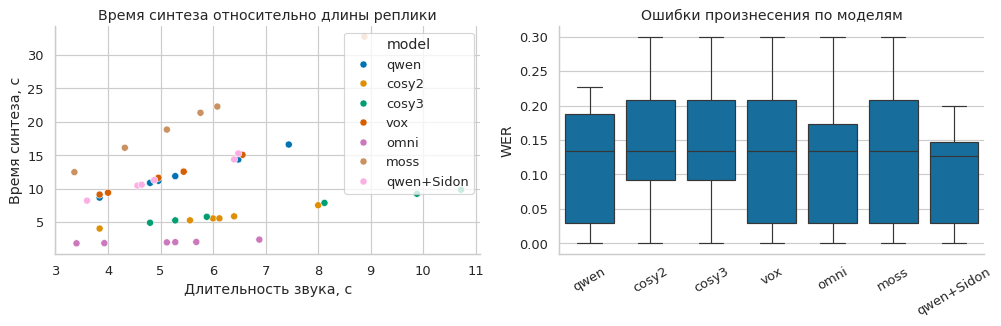

Dropdown(description='Пример:', options=(('Реплика 1', 0), ('Реплика 2', 1), ('Реплика 3', 2), ('Реплика 4', 3…

Output()

In [13]:
if results:
    with stage("Подготовка оценщиков"):
        shell(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "transformers==4.57.3",
                "huggingface_hub==0.36.0",
                "accelerate",
                "speechbrain==1.1.2",
                "torchaudio",
            ]
        )
        import torch
        from transformers import AutoFeatureExtractor, AutoTokenizer, pipeline
        from speechbrain.inference.speaker import EncoderClassifier
        from speechbrain.utils.fetching import FetchConfig, LocalStrategy

        ASR_MODEL = "openai/whisper-large-v3-turbo"
        ASR_REVISION = "41f01f3fe87f28c78e2fbf8b568835947dd65ed9"

        def whisper_preprocessing():
            # Локальная загрузка не запрашивает необязательные chat templates.
            # Сначала обеспечиваем полный набор небольших файлов, включая токенизатор.
            files = (
                "added_tokens.json", "config.json", "generation_config.json",
                "merges.txt", "normalizer.json", "preprocessor_config.json",
                "special_tokens_map.json", "tokenizer.json", "tokenizer_config.json",
                "vocab.json",
            )
            for name in tqdm(files, desc="Whisper · токенизатор и настройки"):
                asset = Path(hf_hub_download(
                    ASR_MODEL, name, revision=ASR_REVISION,
                    cache_dir=WEIGHTS_CACHE / "hf/hub",
                ))
            local = str(asset.parent)
            tokenizer = AutoTokenizer.from_pretrained(local, local_files_only=True)
            extractor = AutoFeatureExtractor.from_pretrained(local, local_files_only=True)
            return tokenizer, extractor

        asr_tokenizer, asr_extractor = whisper_preprocessing()
        asr = pipeline(
            "automatic-speech-recognition",
            model=ASR_MODEL,
            revision=ASR_REVISION,
            tokenizer=asr_tokenizer,
            feature_extractor=asr_extractor,
            model_kwargs={"cache_dir": str(WEIGHTS_CACHE / "hf/hub")},
            device=0,
            dtype=torch.float16,
        )
        encoder = EncoderClassifier.from_hparams(
            source="speechbrain/spkrec-ecapa-voxceleb",
            savedir=str(WEIGHTS_CACHE / "ecapa"),
            local_strategy=LocalStrategy.COPY,
            fetch_config=FetchConfig(
                huggingface_cache_dir=str(WEIGHTS_CACHE / "hf/hub")
            ),
            run_opts={"device": "cuda"},
        )
    import torchaudio
    from jiwer import wer, cer

    def norm(s):
        return " ".join(re.sub(r"[^a-z0-9' ]", " ", s.lower()).split())

    def embedding(path):
        wave, sr = sf.read(path, dtype="float32")
        wave = torch.from_numpy(wave).reshape(1, -1)
        wave = torchaudio.functional.resample(wave, sr, 16000).to("cuda")
        return encoder.encode_batch(wave).detach().flatten()

    metrics = []
    metric_begin = time.monotonic()
    with stage("Разборчивость и голос", counted=True):
        baseline = []
        for j in tqdm(jobs, desc="ASR исходных реплик"):
            if compute + time.monotonic() - metric_begin >= LIMIT:
                break
            predicted = asr(
                j["original"],
                generate_kwargs={"language": "english", "task": "transcribe"},
            )["text"]
            baseline.append(
                {"id": j["id"], "wer": wer(norm(j["text"]), norm(predicted))}
            )
        pd.DataFrame(baseline).to_csv(OUT / "original-wer.csv", index=False)
        for r in tqdm(results, desc="Сгенерированные реплики"):
            if compute + time.monotonic() - metric_begin > LIMIT:
                print("Лимит метрик исчерпан; выводим только фактически измеренное")
                break
            j = jobs[r["id"]]
            prediction = asr(
                r["file"], generate_kwargs={"language": "english", "task": "transcribe"}
            )["text"]
            sim = torch.nn.functional.cosine_similarity(
                embedding(r["file"]), embedding(j["original"]), dim=0
            ).item()
            metrics.append(
                {
                    **r,
                    "wer": wer(norm(j["text"]), norm(prediction)),
                    "cer": cer(norm(j["text"]), norm(prediction)),
                    "similarity": sim,
                    "duration_error": abs(r["seconds"] - j["window"]),
                }
            )
    scores = pd.DataFrame(
        metrics,
        columns=list(results[0]) + ["wer", "cer", "similarity", "duration_error"],
    )
    scores[["wer", "cer", "similarity", "duration_error", "time", "rtf"]] = scores[
        ["wer", "cer", "similarity", "duration_error", "time", "rtf"]
    ].astype(float)
    scores.to_csv(OUT / "metrics.csv", index=False)
    display(
        scores.groupby("model")[["wer", "similarity", "rtf", "time", "duration_error"]]
        .mean()
        .rename(
            columns={
                "wer": "WER",
                "similarity": "Сходство голоса",
                "rtf": "RTF",
                "time": "Время, с",
                "duration_error": "Ошибка длительности, с",
            }
        )
    )
    if not scores.empty:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        if scores.empty:
            print(
                "Метрики не рассчитаны: исчерпан бюджет; пустые графики не являются измерениями."
            )
        sns.scatterplot(data=scores, x="seconds", y="time", hue="model", ax=axes[0])
        axes[0].set(
            title="Время синтеза относительно длины реплики",
            xlabel="Длительность звука, с",
            ylabel="Время синтеза, с",
        )
        sns.boxplot(data=scores, x="model", y="wer", ax=axes[1])
        axes[1].set(title="Ошибки произнесения по моделям", xlabel="", ylabel="WER")
        axes[1].tick_params(axis="x", rotation=30)
        plt.tight_layout()
        plt.show()

    import ipywidgets as widgets
    from IPython.display import clear_output

    # Одновременно показываем только один пример, а не десятки аудиоплееров.
    example = widgets.Dropdown(
        options=[(f"Реплика {i + 1}", i) for i in range(len(jobs))],
        description="Пример:",
    )
    players = widgets.Output()

    def show_example(change=None):
        identifier = example.value
        with players:
            clear_output(wait=True)
            display(
                HTML(
                    "<h3>"
                    + __import__("html").escape(jobs[identifier]["text"])
                    + "</h3>"
                )
            )
            for name, file in [("Оригинал", jobs[identifier]["original"])] + [
                (r["model"], r["file"]) for r in results if r["id"] == identifier
            ]:
                display(
                    HTML("<strong>" + __import__("html").escape(name) + "</strong>")
                )
                if sf.info(file).duration <= 15:
                    player = Audio(filename=file)._repr_html_()
                    display(HTML(player.replace("<audio ", '<audio preload="none" ')))
                else:
                    print("Запись длиннее 15 с; полное аудио сохранено в файле.")

    example.observe(show_example, names="value")
    display(example, players)
    show_example()
else:
    print("Синтез не выполнен: метрики не создаются вместо реальных результатов.")


## 10. WavLM Large SV: второй оценщик голоса
Используем WavLM с обученной головой speaker verification из официального UniSpeech. Это даёт вторую оценку сходства голоса наряду с ECAPA.

Сравниваем одни и те же пары оригинал/синтез. Значения разных оценщиков не следует напрямую смешивать в одну шкалу. Подготовка модели учитывается отдельно; расчёт сходства входит в оставшийся вычислительный бюджет.


In [19]:
import importlib.util
from urllib.request import urlopen

if not GPU or not torch.cuda.is_available():
    print("WavLM SV пропущен: включи GPU в настройках ноутбука.")
elif not results or compute >= LIMIT:
    print("WavLM SV пропущен: нет результатов или исчерпан лимит времени.")
else:
    sv = None
    try:
        with stage("WavLM SV · подготовка"):
            if importlib.util.find_spec("transformers") is None:
                shell([sys.executable, "-m", "pip", "install", "-q", "transformers"])

            WEIGHTS_CACHE.mkdir(parents=True, exist_ok=True)
            revision = "f48fe23232346069dd6f089a424e15858c920edd"
            backend_path = WEIGHTS_CACHE / f"wavlm_sv_{revision}.py"

            if not backend_path.is_file():
                url = (
                    "https://raw.githubusercontent.com/huggingface/open-tts-leaderboard/"
                    f"{revision}/transformers/score_similarity.py"
                )
                with urlopen(url, timeout=60) as response:
                    source = response.read()
                backend_path.write_bytes(source)

            spec = importlib.util.spec_from_file_location("wavlm_sv_backend", backend_path)
            backend = importlib.util.module_from_spec(spec)
            spec.loader.exec_module(backend)

            weight = WEIGHTS_CACHE / "wavlm-large-sv.pth"
            cached_weight = (
                str(weight) if weight.is_file() and weight.stat().st_size == 1_301_926_579
                else None
            )
            checkpoint = backend._resolve_wavlm_seed_tts_checkpoint(
                cached_weight,
                backend.WAVLM_SEED_TTS_REPO_ID,
                backend.WAVLM_SEED_TTS_FILENAME,
                backend.WAVLM_SEED_TTS_SHA256,
            )
            sv = backend.WavLMSeedTtsEmbedder(
                checkpoint, backend.WAVLM_BACKBONE_CONFIG_ID, "cuda", torch.float32
            )

        def sv_embed(file):
            wave, rate = sf.read(file, dtype="float32", always_2d=True)
            if len(wave) == 0:
                return None
            mono = torch.from_numpy(wave.mean(axis=1))
            mono = torchaudio.functional.resample(mono, rate, sv.sampling_rate)
            if mono.numel() < sv.min_samples:
                return None
            return sv([mono.numpy()])

        voice = []
        skipped_short = 0
        sv_start = time.monotonic()

        with stage("WavLM SV · сходство", counted=True):
            for r in tqdm(results, desc="WavLM · пары"):
                if compute + time.monotonic() - sv_start >= LIMIT:
                    break

                a = sv_embed(r["file"])
                b = sv_embed(jobs[r["id"]]["original"])
                if a is None or b is None:
                    skipped_short += 1
                    continue

                voice.append({
                    "model": r["model"],
                    "id": r["id"],
                    "similarity": torch.nn.functional.cosine_similarity(a, b, dim=-1).item(),
                })

        scores = pd.DataFrame(voice, columns=["model", "id", "similarity"])
        OUT.mkdir(parents=True, exist_ok=True)
        scores.to_csv(OUT / "wavlm.csv", index=False)
        if skipped_short:
            print(f"WavLM SV: пропущено слишком коротких пар — {skipped_short}")
        display(scores.groupby("model")["similarity"].mean().rename("Сходство WavLM"))
    finally:
        del sv
        torch.cuda.empty_cache()

WavLM · пары:   0%|          | 0/42 [00:00<?, ?it/s]

model
cosy2         0.430637
cosy3         0.477777
moss          0.510505
omni          0.528166
qwen          0.315782
qwen+Sidon    0.476584
vox           0.545442
Name: Сходство WavLM, dtype: float64

## 11. EN→RU: три примера общего конвейера
В конце показываем ровно три примера: английская реплика → русский перевод OPUS-MT → озвучка Qwen с тем же референсом голоса. Это демонстрация связки компонентов, а не полноценный бенчмарк перевода или русского TTS.

Для демонстрации используем Bazinga. Тексты FLORES сюда не попадают. Время этого блока показываем отдельно; оно не входит в основной 20-минутный эксперимент.


In [20]:
def audio_comparison(original_html, russian_html):
    return HTML(
        '<div style="display:flex;flex-wrap:wrap;gap:24px">'
        '<div><strong>Оригинал (EN)</strong><br>'
        + original_html
        + '</div><div><strong>Русская озвучка (RU)</strong><br>'
        + russian_html
        + '</div></div>'
    )


if GPU and "qwen" in interpreters:
    with stage("EN→RU · демонстрация"):
        shell(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "sentencepiece",
                "sacremoses",
            ]
        )
        from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

        translator = "Helsinki-NLP/opus-mt-en-ru"
        tok = AutoTokenizer.from_pretrained(
            translator, cache_dir=WEIGHTS_CACHE / "hf/hub"
        )
        mt = AutoModelForSeq2SeqLM.from_pretrained(
            translator, cache_dir=WEIGHTS_CACHE / "hf/hub"
        )
        demos = []
        for j in tqdm(jobs[:3], desc="Перевод трёх реплик"):
            prediction = mt.generate(
                **tok(j["text"], return_tensors="pt"), max_new_tokens=128
            )
            demos.append(
                {
                    **j,
                    "text": tok.decode(prediction[0], skip_special_tokens=True),
                    "language": "Russian",
                }
            )
        del mt
        # Release evaluator GPU memory before the synthesis subprocess.
        if "asr" in globals():
            del asr
        if "encoder" in globals():
            del encoder
        torch.cuda.empty_cache()
        path = OUT / "ru-jobs.json"
        path.write_text(json.dumps(demos, ensure_ascii=False))
        run = subprocess.run(
            [
                interpreters["qwen"],
                str(worker),
                "qwen",
                paths["qwen"],
                str(path),
                str(OUT / "ru"),
            ],
            capture_output=True,
            text=True,
            timeout=600,
        )
        (OUT / "ru.log").write_text(run.stderr)
        for j in demos:
            print(jobs[j["id"]]["text"], "→", j["text"])
            wav = OUT / "ru" / f"{j['id']}.wav"
            if wav.exists() and sf.info(wav).duration <= 15:
                display(
                    audio_comparison(
                        Audio(filename=j["original"])._repr_html_(),
                        Audio(filename=str(wav))._repr_html_(),
                    )
                )
            else:
                print("Нет допустимого аудио; проверьте журнал ru.log")


Перевод трёх реплик:   0%|          | 0/3 [00:00<?, ?it/s]

So if a photon is directed through a plane with two slits in it and either slit is observed it will not go through both slits . → Так что, если фотон направлен через плоскость с двумя щелями в ней и любой из них замечен, он не пройдет через обе щели.


A little extra money to get fractional T1 bandwidth in the apartment . → Немного дополнительных денег, чтобы получить часть полосы Т1 в квартире.


I ' m not going to engage in hypotheticals here , I ' m just trying to be a good neighbor . → Я не собираюсь делать гипотезы, я просто пытаюсь быть хорошим соседом.


## 12. Итоги и ограничения
Таблица ниже показывает, на что ушло время: отдельно полный Run all и операции внутри вычислительного лимита. Сравнение можно считать полным только если каждая доступная модель обработала всю общую выборку и оценщики успели посчитать метрики.

Проверьте статусы ошибок и число готовых реплик. Модель, пропущенная из-за несовместимого GPU, не участвует в рейтинге. Если бюджет исчерпан, сохранённые частичные результаты полезны для диагностики, но не заменяют завершённый эксперимент.


In [21]:
display(pd.DataFrame(timings))
print(
    f"Полное время: {time.perf_counter()-START:.1f} с; учтённые вычисления: {compute:.1f} с"
)
print(f'Полных TTS-моделей: {sum(s["Статус"]=="завершена" for s in statuses)} / 7')
print("20-минутный GPU-профиль не подтверждён до полного успешного прогона.")

(OUT / "environment.txt").write_text(
    subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True)
)


,Этап,Секунды,В лимите
0,Разметка Bazinga · локальный кэш / архив Drive,3.813588,False
1,Пять аудиодорожек · локальная копия / кэш Drive,0.646172,False
2,Сборка реплик,33.605036,False
3,FLORES · кэш и статистика,4.952079,False
4,qwen · SDK и CUDA,71.105556,False
5,qwen · веса: кэш / загрузка,5.060238,False
6,qwen · проверка файлов,15.066136,False
7,cosy2 · SDK и CUDA,94.161301,False
8,cosy2 · веса: кэш / загрузка,13.597984,False
9,cosy2 · проверка файлов,11.705210,False


Полное время: 3454.9 с; учтённые вычисления: 490.1 с
Полных TTS-моделей: 7 / 7
20-минутный GPU-профиль не подтверждён до полного успешного прогона.


18183